## Getting the TF workbench ready
The first thing we need to do in our jupyter notebook is to
1. load the TF program
2. load the TF database

In [115]:
# First, I have to laod different modules that I use for analyzing the data and for plotting:
import sys, os, collections
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt; plt.rcdefaults()
from matplotlib.pyplot import figure
from collections import Counter

In [116]:
# First we load the TF program
from tf.fabric import Fabric
from tf.app import use

In [117]:
%%time
# Now we load a few databases
#BHSaLatest = use('etcbc/bhsa:latest')
#BHSaC = use('etcbc/bhsa', version='c', mod='CenterBLC/BHSaddons/tf')
#BHSa2017 = use('etcbc/bhsa', version='2017', mod='CenterBLC/BHSaddons/tf')

BHS = use('etcbc/bhsa', version="2021", mod='CenterBLC/BHSaddons/tf', hoist=globals())
bhsF, bhsL, bhsT, bhsS = BHS.api.F, BHS.api.L, BHS.api.T, BHS.api.S

LXX = use("CenterBLC/LXX", version="1935", hoist=globals())
lxxF, lxxL, lxxT, lxxS = LXX.api.F, LXX.api.L, LXX.api.T, LXX.api.S

DSS = use('etcbc/dss', hoist=globals())
dssF, dssL, dssT, dssS = DSS.api.F, DSS.api.L, DSS.api.T, DSS.api.S

GNT = use ("CenterBLC/N1904", version="1.0.0", mod="CenterBLC/N1904/BOLcomplement/tf/", hoist=globals())
gntF, gntL, gntT, gntS = GNT.api.F, GNT.api.L, GNT.api.T, GNT.api.S

**Locating corpus resources ...**

Name,# of nodes,# slots / node,% coverage
book,39,10938.21,100
chapter,929,459.19,100
lex,9230,46.22,100
verse,23213,18.38,100
half_verse,45179,9.44,100
sentence,63717,6.70,100
sentence_atom,64514,6.61,100
clause,88131,4.84,100
clause_atom,90704,4.70,100
phrase,253203,1.68,100


**Locating corpus resources ...**

Name,# of nodes,# slots / node,% coverage
book,57,10941.98,100
chapter,1192,523.23,100
verse,30371,20.54,100
subverse,30419,20.50,100
word,623693,1.00,100


**Locating corpus resources ...**

Name,# of nodes,# slots / node,% coverage
scroll,1001,1428.81,100
lex,10450,129.14,94
fragment,11182,127.91,100
line,52895,27.04,100
clause,125,12.85,0
cluster,101099,6.68,47
phrase,315,5.10,0
word,500995,2.81,99
sign,1430241,1.00,100


**Locating corpus resources ...**

Name,# of nodes,# slots / node,% coverage
book,27,5102.93,100
chapter,260,529.92,100
verse,7944,17.34,100
sentence,8011,17.20,100
group,8945,7.01,46
clause,42506,8.36,258
wg,106868,6.88,533
phrase,69007,1.90,95
subphrase,116178,1.60,135
word,137779,1.00,100


Display is setup for viewtype [syntax-view](https://github.com/saulocantanhede/tfgreek2/blob/main/docs/syntax-view.md#start)

See [here](https://github.com/saulocantanhede/tfgreek2/blob/main/docs/viewtypes.md#start) for more information on viewtypes

CPU times: user 14.5 s, sys: 2.11 s, total: 16.6 s
Wall time: 17.3 s


# Valence of Fear

## General statistics

In [118]:
FearValence1 = '''
verse verse book chapter
  clause
    phrase function typ
      word lex=JR>[ vs vt lex_utf8 gn nu ps sp
    phrase function typ
      word lex lex_utf8 vs vt gn nu ps sp
'''
FearValence1  = BHS.search(FearValence1)
BHS.table(FearValence1, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  1.10s 1413 results


n,p,verse,clause,phrase,word,phrase,word
1,Genesis 3:10,,וָאִירָ֛א,אִירָ֛א,אִירָ֛א,וָ,וָ
2,Genesis 3:10,,וָאִירָ֛א,אִירָ֛א,אִירָ֛א,אִירָ֛א,אִירָ֛א
3,Genesis 15:1,,אַל־תִּירָ֣א,תִּירָ֣א,תִּירָ֣א,אַל־,אַל־


In [119]:
BHS.export(FearValence1, toDir='/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/', toFile='FearValDataExport_all.tsv')

In [120]:
FearValData_all=pd.read_csv('/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/FearValDataExport_all.tsv',delimiter='\t',encoding='utf-16')
pd.set_option('display.max_columns', 50)
FearValData_all.head(20)

,R,S1,S2,S3,NODE1,TYPE1,TEXT1,book1,chapter1,verse1,NODE2,TYPE2,TEXT2,NODE3,TYPE3,TEXT3,function3,typ3,NODE4,TYPE4,TEXT4,gn4,lex4,lex_utf84,nu4,ps4,sp4,vs4,vt4,NODE5,TYPE5,TEXT5,function5,typ5,NODE6,TYPE6,TEXT6,gn6,lex6,lex_utf86,nu6,ps6,sp6,vs6,vt6
0,1,Genesis,3,10,1414454,verse,וַיֹּ֕אמֶר אֶת־קֹלְךָ֥ שָׁמַ֖עְתִּי בַּגָּ֑ן ו...,Genesis,3,10,427818,clause,וָאִירָ֛א,652349,phrase,אִירָ֛א,Pred,VP,1364,word,אִירָ֛א,unknown,JR>[,ירא,sg,p1,verb,qal,wayq,652348,phrase,וָ,Conj,CP,1363,word,וָ,NaN,W,ו,NaN,NaN,conj,NaN,NaN
1,2,Genesis,3,10,1414454,verse,וַיֹּ֕אמֶר אֶת־קֹלְךָ֥ שָׁמַ֖עְתִּי בַּגָּ֑ן ו...,Genesis,3,10,427818,clause,וָאִירָ֛א,652349,phrase,אִירָ֛א,Pred,VP,1364,word,אִירָ֛א,unknown,JR>[,ירא,sg,p1,verb,qal,wayq,652349,phrase,אִירָ֛א,Pred,VP,1364,word,אִירָ֛א,unknown,JR>[,ירא,sg,p1,verb,qal,wayq
2,3,Genesis,15,1,1414750,verse,אַחַ֣ר׀ הַדְּבָרִ֣ים הָאֵ֗לֶּה הָיָ֤ה דְבַר־יְ...,Genesis,15,1,428731,clause,אַל־תִּירָ֣א,655223,phrase,תִּירָ֣א,Pred,VP,6686,word,תִּירָ֣א,m,JR>[,ירא,sg,p2,verb,qal,impf,655222,phrase,אַל־,Nega,NegP,6685,word,אַל־,NaN,>L=,אל,NaN,NaN,nega,NaN,NaN
3,4,Genesis,15,1,1414750,verse,אַחַ֣ר׀ הַדְּבָרִ֣ים הָאֵ֗לֶּה הָיָ֤ה דְבַר־יְ...,Genesis,15,1,428731,clause,אַל־תִּירָ֣א,655223,phrase,תִּירָ֣א,Pred,VP,6686,word,תִּירָ֣א,m,JR>[,ירא,sg,p2,verb,qal,impf,655223,phrase,תִּירָ֣א,Pred,VP,6686,word,תִּירָ֣א,m,JR>[,ירא,sg,p2,verb,qal,impf
4,5,Genesis,18,15,1414828,verse,וַתְּכַחֵ֨שׁ שָׂרָ֧ה׀ לֵאמֹ֛ר לֹ֥א צָחַ֖קְתִּי...,Genesis,18,15,429019,clause,כִּ֣י׀ יָרֵ֑אָה,656102,phrase,יָרֵ֑אָה,Pred,VP,8069,word,יָרֵ֑אָה,f,JR>[,ירא,sg,p3,verb,qal,perf,656101,phrase,כִּ֣י׀,Conj,CP,8068,word,כִּ֣י׀,NaN,KJ,כי,NaN,NaN,conj,NaN,NaN
5,6,Genesis,18,15,1414828,verse,וַתְּכַחֵ֨שׁ שָׂרָ֧ה׀ לֵאמֹ֛ר לֹ֥א צָחַ֖קְתִּי...,Genesis,18,15,429019,clause,כִּ֣י׀ יָרֵ֑אָה,656102,phrase,יָרֵ֑אָה,Pred,VP,8069,word,יָרֵ֑אָה,f,JR>[,ירא,sg,p3,verb,qal,perf,656102,phrase,יָרֵ֑אָה,Pred,VP,8069,word,יָרֵ֑אָה,f,JR>[,ירא,sg,p3,verb,qal,perf
6,7,Genesis,19,30,1414876,verse,וַיַּעַל֩ לֹ֨וט מִצֹּ֜ועַר וַיֵּ֣שֶׁב בָּהָ֗ר ...,Genesis,19,30,429249,clause,כִּ֥י יָרֵ֖א,656771,phrase,יָרֵ֖א,Pred,VP,9075,word,יָרֵ֖א,m,JR>[,ירא,sg,p3,verb,qal,perf,656770,phrase,כִּ֥י,Conj,CP,9074,word,כִּ֥י,NaN,KJ,כי,NaN,NaN,conj,NaN,NaN
7,8,Genesis,19,30,1414876,verse,וַיַּעַל֩ לֹ֨וט מִצֹּ֜ועַר וַיֵּ֣שֶׁב בָּהָ֗ר ...,Genesis,19,30,429249,clause,כִּ֥י יָרֵ֖א,656771,phrase,יָרֵ֖א,Pred,VP,9075,word,יָרֵ֖א,m,JR>[,ירא,sg,p3,verb,qal,perf,656771,phrase,יָרֵ֖א,Pred,VP,9075,word,יָרֵ֖א,m,JR>[,ירא,sg,p3,verb,qal,perf
8,9,Genesis,20,8,1414892,verse,וַיַּשְׁכֵּ֨ם אֲבִימֶ֜לֶךְ בַּבֹּ֗קֶר וַיִּקְר...,Genesis,20,8,429326,clause,וַיִּֽירְא֥וּ הָאֲנָשִׁ֖ים מְאֹֽד׃,657007,phrase,יִּֽירְא֥וּ,Pred,VP,9421,word,יִּֽירְא֥וּ,m,JR>[,ירא,pl,p3,verb,qal,wayq,657006,phrase,וַ,Conj,CP,9420,word,וַ,NaN,W,ו,NaN,NaN,conj,NaN,NaN
9,10,Genesis,20,8,1414892,verse,וַיַּשְׁכֵּ֨ם אֲבִימֶ֜לֶךְ בַּבֹּ֗קֶר וַיִּקְר...,Genesis,20,8,429326,clause,וַיִּֽירְא֥וּ הָאֲנָשִׁ֖ים מְאֹֽד׃,657007,phrase,יִּֽירְא֥וּ,Pred,VP,9421,word,יִּֽירְא֥וּ,m,JR>[,ירא,pl,p3,verb,qal,wayq,657007,phrase,יִּֽירְא֥וּ,Pred,VP,9421,word,יִּֽירְא֥וּ,m,JR>[,ירא,pl,p3,verb,qal,wayq


In [121]:
# Rename columns
FearValData_all = FearValData_all.rename(columns={
    "R": "order",
    "book1": "book",
    "chapter1": "chapter",
    "verse1": "verse",
    "function5": "function",
    "NODE2": "clause #",
    "NODE5": "phrase #",
    "typ5": "type",
    "TEXT6":"text",
    "lex6": "lexeme_trnslt",
    "lex_utf86": "lexeme",
    "sp6": "part of speech",
    "nu6": "number",
    "ps6": "person",
    "gn6": "gender",
    "vs6": "stem",
    "vt6": "tense"
})

# Reduce DataFrame to the selected columns in the desired order
FearValData_all = FearValData_all[
    [
        "order",
        "book",
        "chapter",
        "verse",
        "clause #",
        "phrase #",
        "text",
        "function",
        "type",
        "gender",
        "lexeme_trnslt",
        "lexeme",
        "part of speech",
        "number",
        "person",
        "stem",
        "tense",
    ]
]
FearValData_all.head()



,order,book,chapter,verse,clause #,phrase #,text,function,type,gender,lexeme_trnslt,lexeme,part of speech,number,person,stem,tense
0,1,Genesis,3,10,427818,652348,וָ,Conj,CP,NaN,W,ו,conj,NaN,NaN,NaN,NaN
1,2,Genesis,3,10,427818,652349,אִירָ֛א,Pred,VP,unknown,JR>[,ירא,verb,sg,p1,qal,wayq
2,3,Genesis,15,1,428731,655222,אַל־,Nega,NegP,NaN,>L=,אל,nega,NaN,NaN,NaN,NaN
3,4,Genesis,15,1,428731,655223,תִּירָ֣א,Pred,VP,m,JR>[,ירא,verb,sg,p2,qal,impf
4,5,Genesis,18,15,429019,656101,כִּ֣י׀,Conj,CP,NaN,KJ,כי,conj,NaN,NaN,NaN,NaN


In [122]:
import re

# Shin/sin dots
SHIN_DOT = "\u05C1"  # שׁ
SIN_DOT  = "\u05C2"  # שׂ

# Basic consonant mapping (SBL-style)
HEB_TO_SBL = {
    "א": "ʾ",
    "ב": "b",
    "ג": "g",
    "ד": "d",
    "ה": "h",
    "ו": "w",
    "ז": "z",
    "ח": "ḥ",
    "ט": "ṭ",
    "י": "y",
    "כ": "k", "ך": "k",
    "ל": "l",
    "מ": "m", "ם": "m",
    "נ": "n", "ן": "n",
    "ס": "s",
    "ע": "ʿ",
    "פ": "p", "ף": "p",
    "צ": "ṣ", "ץ": "ṣ",
    "ק": "q",
    "ר": "r",
    "ת": "t",
    # "ש" handled specially below
}

# remove Hebrew vowel points/cantillation (keep consonants; handle shin/sin separately first)
HEBREW_MARKS_RE = re.compile(r"[\u0591-\u05BD\u05BF-\u05C7]")

def translit_lexeme_sbl(s: str) -> str:
    if s is None:
        return s
    s = str(s)

    # Handle שׁ / שׂ explicitly
    s = s.replace("ש" + SHIN_DOT, "Š")  # temp token
    s = s.replace("ש" + SIN_DOT,  "Ś")  # temp token

    # Drop remaining Hebrew marks (vowels, cantillation, etc.)
    s = HEBREW_MARKS_RE.sub("", s)

    out = []
    for ch in s:
        if ch == "ש":
            out.append("š")     # default when dot is absent
        elif ch == "Š":
            out.append("š")
        elif ch == "Ś":
            out.append("ś")
        else:
            out.append(HEB_TO_SBL.get(ch, ch))  # keep unknown chars as-is
    return "".join(out)

# Create a new transliteration column
FearValData_all["lexeme_sbl"] = FearValData_all["lexeme"].apply(translit_lexeme_sbl)
FearValData_all.head()



,order,book,chapter,verse,clause #,phrase #,text,function,type,gender,lexeme_trnslt,lexeme,part of speech,number,person,stem,tense,lexeme_sbl
0,1,Genesis,3,10,427818,652348,וָ,Conj,CP,NaN,W,ו,conj,NaN,NaN,NaN,NaN,w
1,2,Genesis,3,10,427818,652349,אִירָ֛א,Pred,VP,unknown,JR>[,ירא,verb,sg,p1,qal,wayq,yrʾ
2,3,Genesis,15,1,428731,655222,אַל־,Nega,NegP,NaN,>L=,אל,nega,NaN,NaN,NaN,NaN,ʾl
3,4,Genesis,15,1,428731,655223,תִּירָ֣א,Pred,VP,m,JR>[,ירא,verb,sg,p2,qal,impf,yrʾ
4,5,Genesis,18,15,429019,656101,כִּ֣י׀,Conj,CP,NaN,KJ,כי,conj,NaN,NaN,NaN,NaN,ky


In [123]:
FearValData_all.head(40)


,order,book,chapter,verse,clause #,phrase #,text,function,type,gender,lexeme_trnslt,lexeme,part of speech,number,person,stem,tense,lexeme_sbl
0,1,Genesis,3,10,427818,652348,וָ,Conj,CP,NaN,W,ו,conj,NaN,NaN,NaN,NaN,w
1,2,Genesis,3,10,427818,652349,אִירָ֛א,Pred,VP,unknown,JR>[,ירא,verb,sg,p1,qal,wayq,yrʾ
2,3,Genesis,15,1,428731,655222,אַל־,Nega,NegP,NaN,>L=,אל,nega,NaN,NaN,NaN,NaN,ʾl
3,4,Genesis,15,1,428731,655223,תִּירָ֣א,Pred,VP,m,JR>[,ירא,verb,sg,p2,qal,impf,yrʾ
4,5,Genesis,18,15,429019,656101,כִּ֣י׀,Conj,CP,NaN,KJ,כי,conj,NaN,NaN,NaN,NaN,ky
5,6,Genesis,18,15,429019,656102,יָרֵ֑אָה,Pred,VP,f,JR>[,ירא,verb,sg,p3,qal,perf,yrʾ
6,7,Genesis,19,30,429249,656770,כִּ֥י,Conj,CP,NaN,KJ,כי,conj,NaN,NaN,NaN,NaN,ky
7,8,Genesis,19,30,429249,656771,יָרֵ֖א,Pred,VP,m,JR>[,ירא,verb,sg,p3,qal,perf,yrʾ
8,9,Genesis,20,8,429326,657006,וַ,Conj,CP,NaN,W,ו,conj,NaN,NaN,NaN,NaN,w
9,10,Genesis,20,8,429326,657007,יִּֽירְא֥וּ,Pred,VP,m,JR>[,ירא,verb,pl,p3,qal,wayq,yrʾ


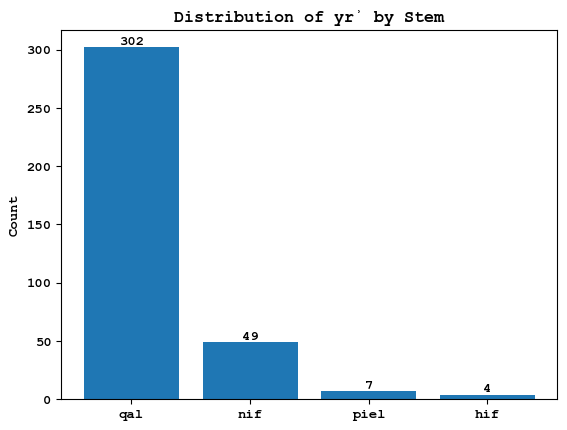

In [124]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams["font.family"] = "Courier New"
mpl.rcParams["font.weight"] = "bold"          # <-- make all text bold
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["axes.titleweight"] = "bold"

# Now plot as usual
stem_counts = FearValData_all["stem"].value_counts().sort_values(ascending=False)

plt.figure()
bars = plt.bar(stem_counts.index, stem_counts.values)

#plt.xlabel("Stem")
plt.ylabel("Count")
plt.title("Distribution of yrʾ by Stem")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

# Save BEFORE show
plt.savefig("fig01_jara_stem_distribution.pdf", bbox_inches="tight")
plt.savefig("fig01_jara_stem_distribution.png", dpi=600, bbox_inches="tight")
plt.show()


In [125]:
import pandas as pd
import matplotlib.pyplot as plt

# Define tense groups
finite = {"perf", "impf", "impv", "wayq"}
nonfinite = {"infc", "infa", "ptca", "ptcp"}

# Filter to Qal only
df_qal = FearValData_all[FearValData_all["stem"] == "qal"].copy()

# Count each group
finite_count = df_qal["tense"].isin(finite).sum()
nonfinite_count = df_qal["tense"].isin(nonfinite).sum()

counts = pd.Series(
    {"finite forms": finite_count,
     "non-finite forms": nonfinite_count}
)

counts


finite forms        260
non-finite forms     42
dtype: int64

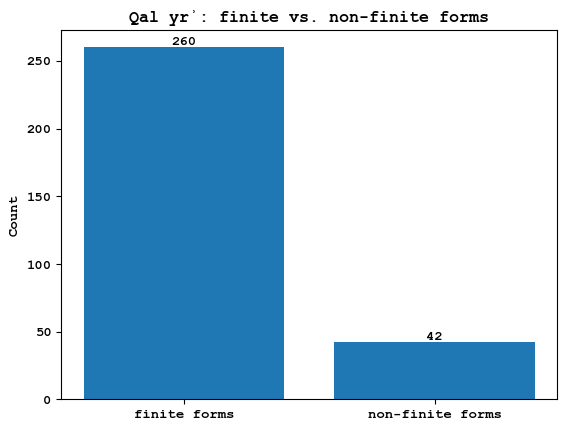

In [126]:
import matplotlib as mpl
mpl.rcParams["font.family"] = "Courier New"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["axes.titleweight"] = "bold"

plt.figure()
bars = plt.bar(counts.index, counts.values)
plt.ylabel("Count")
plt.title("Qal yrʾ: finite vs. non-finite forms")

# add numbers on bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=0, ha="center")
plt.savefig("fig02_jara_qal_finite_vs_nonfinite.pdf", bbox_inches="tight")
plt.savefig("fig02_jara_qal_finite_vs_nonfinite.png", dpi=600, bbox_inches="tight")
plt.show()


## Finite verbal forms in Qal

In [127]:
FearValData_all.head()

,order,book,chapter,verse,clause #,phrase #,text,function,type,gender,lexeme_trnslt,lexeme,part of speech,number,person,stem,tense,lexeme_sbl
0,1,Genesis,3,10,427818,652348,וָ,Conj,CP,NaN,W,ו,conj,NaN,NaN,NaN,NaN,w
1,2,Genesis,3,10,427818,652349,אִירָ֛א,Pred,VP,unknown,JR>[,ירא,verb,sg,p1,qal,wayq,yrʾ
2,3,Genesis,15,1,428731,655222,אַל־,Nega,NegP,NaN,>L=,אל,nega,NaN,NaN,NaN,NaN,ʾl
3,4,Genesis,15,1,428731,655223,תִּירָ֣א,Pred,VP,m,JR>[,ירא,verb,sg,p2,qal,impf,yrʾ
4,5,Genesis,18,15,429019,656101,כִּ֣י׀,Conj,CP,NaN,KJ,כי,conj,NaN,NaN,NaN,NaN,ky


In [128]:
finite_tenses = {"perf", "impf", "wayq", "impv"}

valid_clauses = set(
    FearValData_all.loc[
        (FearValData_all["lexeme_trnslt"] == "JR>[") &
        (FearValData_all["stem"] == "qal") &
        (FearValData_all["tense"].isin(finite_tenses)),
        "clause #"
    ]
)
FearValData_QalFinite = FearValData_all[
    FearValData_all["clause #"].isin(valid_clauses)
].copy()

FearValData_QalFinite.head()


,order,book,chapter,verse,clause #,phrase #,text,function,type,gender,lexeme_trnslt,lexeme,part of speech,number,person,stem,tense,lexeme_sbl
0,1,Genesis,3,10,427818,652348,וָ,Conj,CP,NaN,W,ו,conj,NaN,NaN,NaN,NaN,w
1,2,Genesis,3,10,427818,652349,אִירָ֛א,Pred,VP,unknown,JR>[,ירא,verb,sg,p1,qal,wayq,yrʾ
2,3,Genesis,15,1,428731,655222,אַל־,Nega,NegP,NaN,>L=,אל,nega,NaN,NaN,NaN,NaN,ʾl
3,4,Genesis,15,1,428731,655223,תִּירָ֣א,Pred,VP,m,JR>[,ירא,verb,sg,p2,qal,impf,yrʾ
4,5,Genesis,18,15,429019,656101,כִּ֣י׀,Conj,CP,NaN,KJ,כי,conj,NaN,NaN,NaN,NaN,ky


In [129]:
FearValData_QalFinite.head(10)

,order,book,chapter,verse,clause #,phrase #,text,function,type,gender,lexeme_trnslt,lexeme,part of speech,number,person,stem,tense,lexeme_sbl
0,1,Genesis,3,10,427818,652348,וָ,Conj,CP,NaN,W,ו,conj,NaN,NaN,NaN,NaN,w
1,2,Genesis,3,10,427818,652349,אִירָ֛א,Pred,VP,unknown,JR>[,ירא,verb,sg,p1,qal,wayq,yrʾ
2,3,Genesis,15,1,428731,655222,אַל־,Nega,NegP,NaN,>L=,אל,nega,NaN,NaN,NaN,NaN,ʾl
3,4,Genesis,15,1,428731,655223,תִּירָ֣א,Pred,VP,m,JR>[,ירא,verb,sg,p2,qal,impf,yrʾ
4,5,Genesis,18,15,429019,656101,כִּ֣י׀,Conj,CP,NaN,KJ,כי,conj,NaN,NaN,NaN,NaN,ky
5,6,Genesis,18,15,429019,656102,יָרֵ֑אָה,Pred,VP,f,JR>[,ירא,verb,sg,p3,qal,perf,yrʾ
6,7,Genesis,19,30,429249,656770,כִּ֥י,Conj,CP,NaN,KJ,כי,conj,NaN,NaN,NaN,NaN,ky
7,8,Genesis,19,30,429249,656771,יָרֵ֖א,Pred,VP,m,JR>[,ירא,verb,sg,p3,qal,perf,yrʾ
8,9,Genesis,20,8,429326,657006,וַ,Conj,CP,NaN,W,ו,conj,NaN,NaN,NaN,NaN,w
9,10,Genesis,20,8,429326,657007,יִּֽירְא֥וּ,Pred,VP,m,JR>[,ירא,verb,pl,p3,qal,wayq,yrʾ


In [130]:
FearValData_all.shape

(1413, 18)

In [131]:
FearValData_QalFinite.shape

(911, 18)

In [132]:
phrase_functions_of_interest = {"PreO", "Objc", "Cmpl"}

phrase_distribution = (
    FearValData_QalFinite
    .loc[FearValData_QalFinite["function"].isin(phrase_functions_of_interest)]
    ["function"]
    .value_counts()
)

phrase_distribution

function
Objc    140
Cmpl    129
PreO     12
Name: count, dtype: int64

In [133]:
FearValData_QalFinite["function"].value_counts()


function
Pred    236
Objc    140
Cmpl    129
Conj    122
Nega    121
Subj     72
Time     27
Modi     24
Adju     14
PreO     12
Ques      7
Rela      3
Intj      2
Loca      2
Name: count, dtype: int64

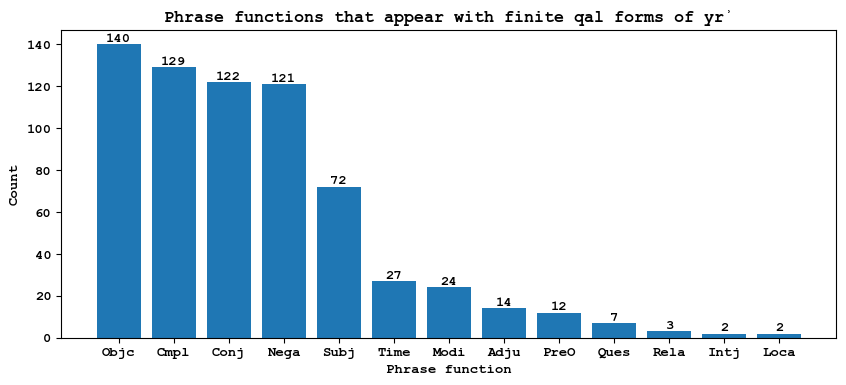

In [134]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# Styling (as before)
mpl.rcParams["font.family"] = "Courier New"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["axes.titleweight"] = "bold"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

# Get counts and exclude 'Pred'
func_counts = (
    FearValData_QalFinite["function"]
    .value_counts()
    .drop("Pred", errors="ignore")
)

# Plot
plt.figure(figsize=(10, 4))
bars = plt.bar(func_counts.index, func_counts.values)

plt.xlabel("Phrase function")
plt.ylabel("Count")
plt.title("Phrase functions that appear with finite qal forms of yrʾ")

# Add count labels
for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        h,
        str(int(h)),
        ha="center",
        va="bottom"
    )

# Save high-resolution outputs
plt.savefig("fig03_jara_qal_finite_phrase_functions_noPred.pdf", bbox_inches="tight")
plt.savefig("fig03_jara_qal_finite_phrase_functions_noPred.png", dpi=600, bbox_inches="tight")

plt.show()


In [135]:
FearValData_QalFinite["type"].value_counts()


type
PP      271
VP      248
CP      125
NegP    121
NP       91
AdvP     24
PrNP     10
PPrP     10
InrP      7
InjP      2
IPrP      2
Name: count, dtype: int64

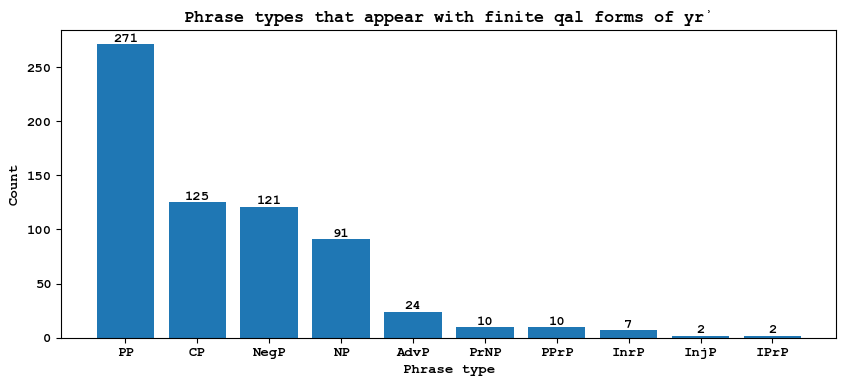

In [136]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# Styling (as before)
mpl.rcParams["font.family"] = "Courier New"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["axes.titleweight"] = "bold"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

# Get counts and exclude 'Pred'
func_counts = (
    FearValData_QalFinite["type"]
    .value_counts()
    .drop("VP", errors="ignore")
)

# Plot
plt.figure(figsize=(10, 4))
bars = plt.bar(func_counts.index, func_counts.values)

plt.xlabel("Phrase type")
plt.ylabel("Count")
plt.title("Phrase types that appear with finite qal forms of yrʾ")

# Add count labels
for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        h,
        str(int(h)),
        ha="center",
        va="bottom"
    )

# Save high-resolution outputs
plt.savefig("fig04_jara_qal_finite_phrase_types_noPred.pdf", bbox_inches="tight")
plt.savefig("fig04_jara_qal_finite_phrase_types_noPred.png", dpi=600, bbox_inches="tight")

plt.show()


In [137]:
import pandas as pd

# 1) keep only Objc / Cmpl phrases
df_oc = FearValData_QalFinite[
    FearValData_QalFinite["function"].isin(["Objc", "Cmpl"])
].copy()

# 2) within those phrases, keep only prepositions
df_prep = df_oc[df_oc["part of speech"] == "prep"].copy()

# 3) pick the first prep per phrase (by order) as the "launcher"
df_prep = df_prep.sort_values("order")
prep_launchers = (
    df_prep
    .groupby(["clause #", "phrase #"], as_index=False)
    .first()
)

# 4) count launcher prepositions by lexeme_sbl
prep_counts = prep_launchers["lexeme_sbl"].value_counts()

prep_counts


lexeme_sbl
mn    51
ʾt    46
l      2
b      1
Name: count, dtype: int64

In [138]:
# How many Objc/Cmpl phrases total?
n_phrases_total = df_oc[["clause #", "phrase #"]].drop_duplicates().shape[0]

# How many of those have at least one prep inside?
n_phrases_with_prep = prep_launchers.shape[0]

n_phrases_total, n_phrases_with_prep


(118, 100)

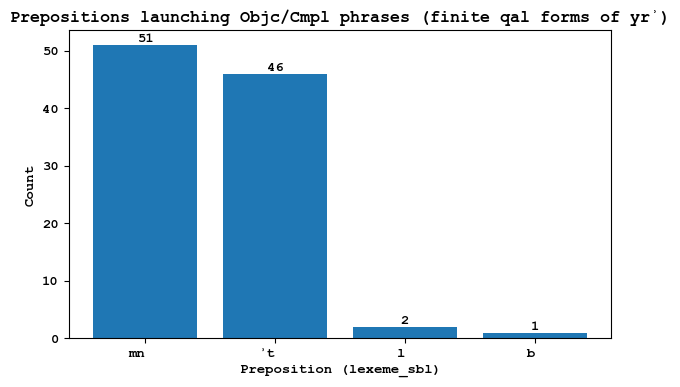

In [139]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams["font.family"] = "Courier New"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["axes.titleweight"] = "bold"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

plt.figure(figsize=(7, 4))
bars = plt.bar(prep_counts.index.astype(str), prep_counts.values)

plt.xlabel("Preposition (lexeme_sbl)")
plt.ylabel("Count")
plt.title("Prepositions launching Objc/Cmpl phrases (finite qal forms of yrʾ)")

# add counts on top
for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        h,
        str(int(h)),
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=0, ha="right")
plt.savefig("fig05_jara_qal_finite_prep_launchers_objc_cmpl.pdf", bbox_inches="tight")
plt.savefig("fig05_jara_qal_finite_prep_launchers_objc_cmpl.png", dpi=600, bbox_inches="tight")
plt.show()


In [140]:
# Count launcher prepositions by book and lexeme_sbl
prep_by_book = (
    prep_launchers
    .groupby(["book", "lexeme_sbl"])
    .size()
    .unstack(fill_value=0)
)

prep_by_book


lexeme_sbl,b,l,mn,ʾt
book,,,,
Chronica_I,0,0,0,1
Deuteronomium,0,0,6,6
Ecclesiastes,0,0,3,2
Exodus,0,0,1,3
Ezechiel,0,0,3,1
Haggai,0,0,1,0
Hosea,0,0,0,1
Iob,0,0,2,0
Jeremia,1,0,5,3


In [141]:
prep_by_book_pct = prep_by_book.div(prep_by_book.sum(axis=1), axis=0) * 100
prep_by_book_pct.round(1)


lexeme_sbl,b,l,mn,ʾt
book,,,,
Chronica_I,0.0,0.0,0.0,100.0
Deuteronomium,0.0,0.0,50.0,50.0
Ecclesiastes,0.0,0.0,60.0,40.0
Exodus,0.0,0.0,25.0,75.0
Ezechiel,0.0,0.0,75.0,25.0
Haggai,0.0,0.0,100.0,0.0
Hosea,0.0,0.0,0.0,100.0
Iob,0.0,0.0,100.0,0.0
Jeremia,11.1,0.0,55.6,33.3


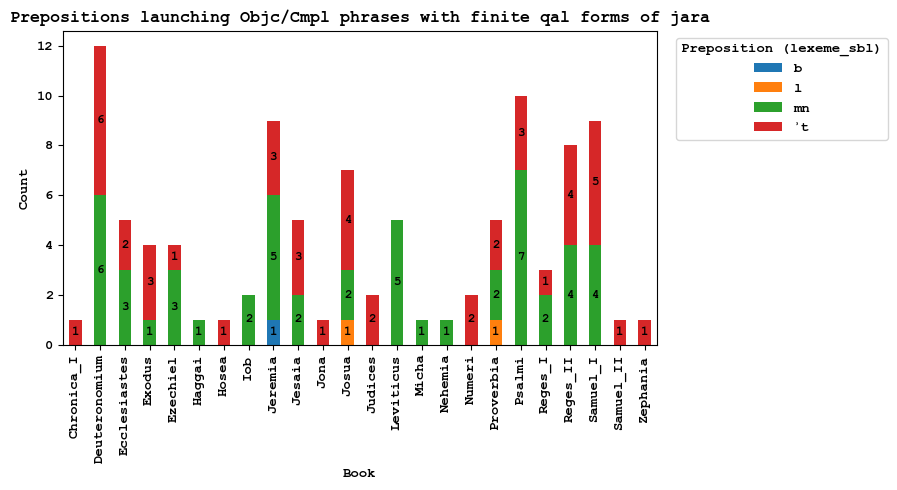

In [142]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams["font.family"] = "Courier New"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["axes.titleweight"] = "bold"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

fig, ax = plt.subplots(figsize=(9, 5))

# Plot stacked bars
prep_by_book.plot(
    kind="bar",
    stacked=True,
    ax=ax
)

ax.set_xlabel("Book")
ax.set_ylabel("Count")
ax.set_title("Prepositions launching Objc/Cmpl phrases with finite qal forms of jara")

# ---- ADD COUNT LABELS ----
for container in ax.containers:
    for bar in container:
        height = bar.get_height()
        if height > 0:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + height / 2,
                f"{int(height)}",
                ha="center",
                va="center",
                fontsize=9
            )

ax.legend(
    title="Preposition (lexeme_sbl)",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "fig06_jara_qal_finite_prep_launchers_by_book.pdf",
    bbox_inches="tight"
)
plt.savefig(
    "fig06_jara_qal_finite_prep_launchers_by_book.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()


## Jara + MN

In [143]:
FearValenceMN1 = '''
verse verse book chapter
  clause
    p1:phrase function typ
      word lex=JR>[ vs=qal vt=perf|impf|wayq|impv lex_utf8 gn nu ps sp g_cons g_lex g_word
    p2:phrase function typ=PP
      w1:word lex=MN lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word
      w2:word lex lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word


p2 =: w1
w1 <: w2

'''
FearValenceMN1  = BHS.search(FearValenceMN1)
BHS.table(FearValenceMN1, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  1.63s 43 results


n,p,verse,clause,phrase,word,phrase,word,word
1,Exodus 9:30,,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,תִּֽירְא֔וּן,תִּֽירְא֔וּן,מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,מִ,פְּנֵ֖י
2,Leviticus 19:14,,וְיָרֵ֥אתָ מֵּאֱלֹהֶ֖יךָ,יָרֵ֥אתָ,יָרֵ֥אתָ,מֵּאֱלֹהֶ֖יךָ,מֵּ,אֱלֹהֶ֖יךָ
3,Leviticus 19:32,,וְיָרֵ֥אתָ מֵּאֱלֹהֶ֖יךָ,יָרֵ֥אתָ,יָרֵ֥אתָ,מֵּאֱלֹהֶ֖יךָ,מֵּ,אֱלֹהֶ֖יךָ


In [144]:
FearValenceMN1 = '''
verse verse book chapter
  clause
    p1:phrase function typ
      word lex=JR>[ vs=qal vt=perf|impf|wayq|impv lex_utf8 gn nu ps sp g_cons g_lex g_word
    p2:phrase function typ=PP
      w1:word lex=MN lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word
      w2:word lex lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word


p2 =: w1

'''
FearValenceMN1  = BHS.search(FearValenceMN1)
BHS.table(FearValenceMN1, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  1.65s 127 results


n,p,verse,clause,phrase,word,phrase,word,word
1,Exodus 9:30,,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,תִּֽירְא֔וּן,תִּֽירְא֔וּן,מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,מִ,מִ
2,Exodus 9:30,,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,תִּֽירְא֔וּן,תִּֽירְא֔וּן,מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,מִ,פְּנֵ֖י
3,Exodus 9:30,,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,תִּֽירְא֔וּן,תִּֽירְא֔וּן,מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,מִ,יְהוָ֥ה


In [145]:
BHS.export(FearValenceMN1+FearValenceMN1, toDir='/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/', toFile='FearValDataExport_MN.tsv')

In [146]:
FearValenceMN=pd.read_csv('/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/FearValDataExport_MN.tsv',delimiter='\t',encoding='utf-16')
pd.set_option('display.max_columns', 50)
FearValenceMN.head(10)

,R,S1,S2,S3,NODE1,TYPE1,TEXT1,book1,chapter1,verse1,NODE2,TYPE2,TEXT2,NODE3,TYPE3,TEXT3,function3,typ3,NODE4,TYPE4,TEXT4,g_cons4,g_lex4,g_word4,gn4,...,g_cons6,g_lex6,g_word6,gn6,lex6,lex_utf86,nu6,ps6,sp6,vs6,vt6,NODE7,TYPE7,TEXT7,g_cons7,g_lex7,g_word7,gn7,lex7,lex_utf87,nu7,ps7,sp7,vs7,vt7
0,1,Exodus,9,30,1416161,verse,וְאַתָּ֖ה וַעֲבָדֶ֑יךָ יָדַ֕עְתִּי כִּ֚י טֶ֣רֶ...,Exodus,9,30,434552,clause,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱ...,672561,phrase,תִּֽירְא֔וּן,Pred,VP,33688,word,תִּֽירְא֔וּן,TJR>WN,JR:>,T.I45JR:>80W.N,m,...,M,MI-,MI-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,33689,word,מִ,M,MI-,MI-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN
1,2,Exodus,9,30,1416161,verse,וְאַתָּ֖ה וַעֲבָדֶ֑יךָ יָדַ֕עְתִּי כִּ֚י טֶ֣רֶ...,Exodus,9,30,434552,clause,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱ...,672561,phrase,תִּֽירְא֔וּן,Pred,VP,33688,word,תִּֽירְא֔וּן,TJR>WN,JR:>,T.I45JR:>80W.N,m,...,M,MI-,MI-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,33690,word,פְּנֵ֖י,PNJ,P.:N,P.:N;73J,m,PNH/,פנה,pl,NaN,subs,NaN,NaN
2,3,Exodus,9,30,1416161,verse,וְאַתָּ֖ה וַעֲבָדֶ֑יךָ יָדַ֕עְתִּי כִּ֚י טֶ֣רֶ...,Exodus,9,30,434552,clause,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱ...,672561,phrase,תִּֽירְא֔וּן,Pred,VP,33688,word,תִּֽירְא֔וּן,TJR>WN,JR:>,T.I45JR:>80W.N,m,...,M,MI-,MI-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,33691,word,יְהוָ֥ה,JHWH,J:HW@H,J:HW@71H,m,JHWH/,יהוה,sg,NaN,nmpr,NaN,NaN
3,4,Exodus,9,30,1416161,verse,וְאַתָּ֖ה וַעֲבָדֶ֑יךָ יָדַ֕עְתִּי כִּ֚י טֶ֣רֶ...,Exodus,9,30,434552,clause,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱ...,672561,phrase,תִּֽירְא֔וּן,Pred,VP,33688,word,תִּֽירְא֔וּן,TJR>WN,JR:>,T.I45JR:>80W.N,m,...,M,MI-,MI-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,33692,word,אֱלֹהִֽים׃,>LHJM,>:ELOH,>:ELOHI75JM,m,>LHJM/,אלהים,pl,NaN,subs,NaN,NaN
4,5,Leviticus,19,14,1417684,verse,לֹא־תְקַלֵּ֣ל חֵרֵ֔שׁ וְלִפְנֵ֣י עִוֵּ֔ר לֹ֥א ...,Leviticus,19,14,439868,clause,וְיָרֵ֥אתָ מֵּאֱלֹהֶ֖יךָ,688998,phrase,יָרֵ֥אתָ,Pred,VP,64020,word,יָרֵ֥אתָ,JR>T,J@R;>,J@R;71>T@,m,...,M,M.;-,M.;-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,64021,word,מֵּ,M,M.;-,M.;-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN
5,6,Leviticus,19,14,1417684,verse,לֹא־תְקַלֵּ֣ל חֵרֵ֔שׁ וְלִפְנֵ֣י עִוֵּ֔ר לֹ֥א ...,Leviticus,19,14,439868,clause,וְיָרֵ֥אתָ מֵּאֱלֹהֶ֖יךָ,688998,phrase,יָרֵ֥אתָ,Pred,VP,64020,word,יָרֵ֥אתָ,JR>T,J@R;>,J@R;71>T@,m,...,M,M.;-,M.;-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,64022,word,אֱלֹהֶ֖יךָ,>LHJK,>:ELOH,>:ELOHE73JK@,m,>LHJM/,אלהים,pl,NaN,subs,NaN,NaN
6,7,Leviticus,19,32,1417702,verse,מִפְּנֵ֤י שֵׂיבָה֙ תָּק֔וּם וְהָדַרְתָּ֖ פְּנֵ...,Leviticus,19,32,439933,clause,וְיָרֵ֥אתָ מֵּאֱלֹהֶ֖יךָ,689206,phrase,יָרֵ֥אתָ,Pred,VP,64307,word,יָרֵ֥אתָ,JR>T,J@R;>,J@R;71>T@,m,...,M,M.;-,M.;-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,64308,word,מֵּ,M,M.;-,M.;-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN
7,8,Leviticus,19,32,1417702,verse,מִפְּנֵ֤י שֵׂיבָה֙ תָּק֔וּם וְהָדַרְתָּ֖ פְּנֵ...,Leviticus,19,32,439933,clause,וְיָרֵ֥אתָ מֵּאֱלֹהֶ֖יךָ,689206,phrase,יָרֵ֥אתָ,Pred,VP,64307,word,יָרֵ֥אתָ,JR>T,J@R;>,J@R;71>T@,m,...,M,M.;-,M.;-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,64309,word,אֱלֹהֶ֖יךָ,>LHJK,>:ELOH,>:ELOHE73JK@,m,>LHJM/,אלהים,pl,NaN,subs,NaN,NaN
8,9,Leviticus,25,17,1417875,verse,וְלֹ֤א תֹונוּ֙ אִ֣ישׁ אֶת־עֲמִיתֹ֔ו וְיָרֵ֖אתָ...,Leviticus,25,17,440526,clause,וְיָרֵ֖אתָ מֵֽאֱלֹהֶ֑יךָ,690982,phrase,יָרֵ֖אתָ,Pred,VP,67465,word,יָרֵ֖אתָ,JR>T,J@R;>,J@R;73>T@,m,...,M,M;-,M;45-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,67466,word,מֵֽ,M,M;-,M;45-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN
9,10,Leviticus,25,17,1417875,verse,וְלֹ֤א תֹונוּ֙ אִ֣ישׁ אֶת־עֲמִיתֹ֔ו וְיָרֵ֖אתָ...,Leviticus,25,17,440526,clause,וְיָרֵ֖אתָ מֵֽאֱלֹהֶ֑יךָ,690982,phrase,יָרֵ֖אתָ,Pred,VP,67465,word,יָרֵ֖אתָ,JR>T,J@R;>,J@R;73>T@,m,...,M,M;-,M;45-,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,67467,word,אֱלֹהֶ֑יךָ,>LHJK,>:ELOH,>:ELOHE92JK@,m,>LHJM/,אלהים,pl,NaN,subs,NaN,NaN


In [147]:
lex7_counts = FearValenceMN["lex7"].value_counts()
lex7_counts

lex7
MN        106
PNH/       40
>LHJM/     12
H          12
DBR/       10
L           6
MLK/        6
JHWH/       6
PXD/        4
KFDJ/       4
XJH/        2
CD/         2
MCPV/       2
RBBH/       2
R</         2
>RY/        2
CMW<H/      2
LJLH/       2
>WT/        2
MJ          2
<M/         2
>CWR/       2
BBL/        2
M<RB/       2
>NWC/       2
<BD/        2
CLMH=/      2
CMW>L/      2
GT=/        2
>KJC/       2
DWD==/      2
PLCTJ/      2
>C/         2
CLG/        2
Name: count, dtype: int64

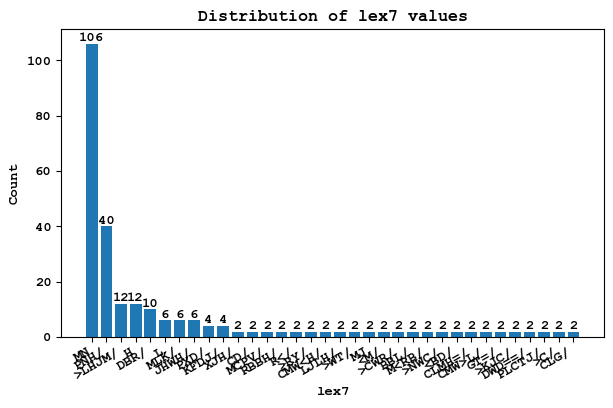

In [148]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# Styling
mpl.rcParams["font.family"] = "Courier New"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["axes.titleweight"] = "bold"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

plt.figure(figsize=(7, 4))

bars = plt.bar(lex7_counts.index.astype(str), lex7_counts.values)

plt.xlabel("lex7")
plt.ylabel("Count")
plt.title("Distribution of lex7 values")

# Add count labels
for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        h,
        str(int(h)),
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=30, ha="right")

# Save outputs
plt.savefig("fig07_lex7_distribution.pdf", bbox_inches="tight")
plt.savefig("fig07_lex7_distribution.png", dpi=600, bbox_inches="tight")

plt.show()


## Jara + >T

In [149]:
FearValenceET1 = '''
verse verse book chapter
  clause
    p1:phrase function typ
      word lex=JR>[ vs=qal vt=perf|impf|wayq|impv lex_utf8 gn nu ps sp g_cons g_lex g_word
    p2:phrase function typ=PP
      w1:word lex=>T lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word
      w2:word lex lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word


p2 =: w1
w1 <: w2

'''
FearValenceET1  = BHS.search(FearValenceET1)
BHS.table(FearValenceET1, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  1.67s 36 results


n,p,verse,clause,phrase,word,phrase,word,word
1,Exodus 1:17,,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,תִּירֶ֤אןָ,תִּירֶ֤אןָ,אֶת־הָ֣אֱלֹהִ֔ים,אֶת־,הָ֣
2,Exodus 1:21,,כִּֽי־יָֽרְא֥וּ הַֽמְיַלְּדֹ֖ת אֶת־הָאֱלֹהִ֑ים,יָֽרְא֥וּ,יָֽרְא֥וּ,אֶת־הָאֱלֹהִ֑ים,אֶת־,הָ
3,Exodus 14:31,,וַיִּֽירְא֥וּ הָעָ֖ם אֶת־יְהוָ֑ה,יִּֽירְא֥וּ,יִּֽירְא֥וּ,אֶת־יְהוָ֑ה,אֶת־,יְהוָ֑ה


In [150]:
FearValenceET2 = '''
verse verse book chapter
  clause
    p1:phrase function typ
      word lex=JR>[ vs=qal vt=perf|impf|wayq|impv lex_utf8 gn nu ps sp g_cons g_lex g_word
    p2:phrase function typ=PP
      w1:word lex=>T lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word
      w2:word lex lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word


p2 =: w1

'''
FearValenceET2  = BHS.search(FearValenceET2)
BHS.table(FearValenceET2, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  1.63s 113 results


n,p,verse,clause,phrase,word,phrase,word,word
1,Exodus 1:17,,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,תִּירֶ֤אןָ,תִּירֶ֤אןָ,אֶת־הָ֣אֱלֹהִ֔ים,אֶת־,אֶת־
2,Exodus 1:17,,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,תִּירֶ֤אןָ,תִּירֶ֤אןָ,אֶת־הָ֣אֱלֹהִ֔ים,אֶת־,הָ֣
3,Exodus 1:17,,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,תִּירֶ֤אןָ,תִּירֶ֤אןָ,אֶת־הָ֣אֱלֹהִ֔ים,אֶת־,אֱלֹהִ֔ים


In [151]:
BHS.export(FearValenceET1+FearValenceET2, toDir='/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/', toFile='FearValDataExport_ET.tsv')

In [152]:
FearValenceET=pd.read_csv('/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/FearValDataExport_ET.tsv',delimiter='\t',encoding='utf-16')
pd.set_option('display.max_columns', 50)
FearValenceET.head(10)

,R,S1,S2,S3,NODE1,TYPE1,TEXT1,book1,chapter1,verse1,NODE2,TYPE2,TEXT2,NODE3,TYPE3,TEXT3,function3,typ3,NODE4,TYPE4,TEXT4,g_cons4,g_lex4,g_word4,gn4,...,g_cons6,g_lex6,g_word6,gn6,lex6,lex_utf86,nu6,ps6,sp6,vs6,vt6,NODE7,TYPE7,TEXT7,g_cons7,g_lex7,g_word7,gn7,lex7,lex_utf87,nu7,ps7,sp7,vs7,vt7
0,1,Exodus,1,17,1415938,verse,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים ו...,Exodus,1,17,433593,clause,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,669693,phrase,תִּירֶ֤אןָ,Pred,VP,29000,word,תִּירֶ֤אןָ,TJR>N,JRE>,T.IJRE70>N@,f,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,29004,word,הָ֣,H,H@-,H@74-,NaN,H,ה,NaN,NaN,art,NaN,NaN
1,2,Exodus,1,21,1415942,verse,וַיְהִ֕י כִּֽי־יָֽרְא֥וּ הַֽמְיַלְּדֹ֖ת אֶת־הָ...,Exodus,1,21,433610,clause,כִּֽי־יָֽרְא֥וּ הַֽמְיַלְּדֹ֖ת אֶת־הָאֱלֹהִ֑ים,669749,phrase,יָֽרְא֥וּ,Pred,VP,29083,word,יָֽרְא֥וּ,JR>W,J@R:>,J@45R:>71W.,unknown,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,29087,word,הָ,H,H@-,H@-,NaN,H,ה,NaN,NaN,art,NaN,NaN
2,3,Exodus,14,31,1416309,verse,וַיַּ֨רְא יִשְׂרָאֵ֜ל אֶת־הַיָּ֣ד הַגְּדֹלָ֗ה ...,Exodus,14,31,435129,clause,וַיִּֽירְא֥וּ הָעָ֖ם אֶת־יְהוָ֑ה,674410,phrase,יִּֽירְא֥וּ,Pred,VP,36902,word,יִּֽירְא֥וּ,JJR>W,JR:>,J.I45JR:>71W.,m,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,36906,word,יְהוָ֑ה,JHWH,J:HW@H,J:HW@92H,m,JHWH/,יהוה,sg,NaN,nmpr,NaN,NaN
3,4,Numbers,14,9,1418506,verse,אַ֣ךְ בַּֽיהוָה֮ אַל־תִּמְרֹדוּ֒ וְאַתֶּ֗ם אַל...,Numeri,14,9,442388,clause,וְאַתֶּ֗ם אַל־תִּֽירְאוּ֙ אֶת־עַ֣ם הָאָ֔רֶץ,696605,phrase,תִּֽירְאוּ֙,Pred,VP,78581,word,תִּֽירְאוּ֙,TJR>W,JR:>,T.I45JR:>W.03,m,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,78583,word,עַ֣ם,<M,<AM,<A74M,m,<M/,עם,sg,NaN,subs,NaN,NaN
4,5,Deuteronomy,6,2,1419478,verse,לְמַ֨עַן תִּירָ֜א אֶת־יְהוָ֣ה אֱלֹהֶ֗יךָ לִ֠שׁ...,Deuteronomium,6,2,445647,clause,לְמַ֨עַן תִּירָ֜א אֶת־יְהוָ֣ה אֱלֹהֶ֗יךָ אַתָּ...,706500,phrase,תִּירָ֜א,Pred,VP,96992,word,תִּירָ֜א,TJR>,JR@>,T.IJR@61>,m,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,96994,word,יְהוָ֣ה,JHWH,J:HW@H,J:HW@74H,m,JHWH/,יהוה,sg,NaN,nmpr,NaN,NaN
5,6,Deuteronomy,6,13,1419489,verse,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ תִּירָ֖א וְאֹתֹ֣ו תַעֲב...,Deuteronomium,6,13,445689,clause,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ תִּירָ֖א,706614,phrase,תִּירָ֖א,Pred,VP,97194,word,תִּירָ֖א,TJR>,JR@>,T.IJR@73>,m,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,97192,word,יְהוָ֧ה,JHWH,J:HW@H,J:HW@94H,m,JHWH/,יהוה,sg,NaN,nmpr,NaN,NaN
6,7,Deuteronomy,10,20,1419596,verse,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ תִּירָ֖א אֹתֹ֣ו תַעֲבֹ֑...,Deuteronomium,10,20,446142,clause,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ תִּירָ֖א,707957,phrase,תִּירָ֖א,Pred,VP,99544,word,תִּירָ֖א,TJR>,JR@>,T.IJR@73>,m,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,99542,word,יְהוָ֧ה,JHWH,J:HW@H,J:HW@94H,m,JHWH/,יהוה,sg,NaN,nmpr,NaN,NaN
7,8,Deuteronomy,31,12,1420130,verse,הַקְהֵ֣ל אֶת־הָעָ֗ם הָֽאֲנָשִׁ֤ים וְהַנָּשִׁים...,Deuteronomium,31,12,448294,clause,וְיָֽרְאוּ֙ אֶת־יְהוָ֣ה אֱלֹֽהֵיכֶ֔ם,714529,phrase,יָֽרְאוּ֙,Pred,VP,110943,word,יָֽרְאוּ֙,JR>W,J@R:>,J@45R:>W.03,unknown,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,110945,word,יְהוָ֣ה,JHWH,J:HW@H,J:HW@74H,m,JHWH/,יהוה,sg,NaN,nmpr,NaN,NaN
8,9,Joshua,4,14,1420314,verse,בַּיֹּ֣ום הַה֗וּא גִּדַּ֤ל יְהוָה֙ אֶת־יְהֹושׁ...,Josua,4,14,449081,clause,כַּאֲשֶׁ֛ר יָרְא֥וּ אֶת־מֹשֶׁ֖ה כָּל־יְמֵ֥י חַ...,716783,phrase,יָרְא֥וּ,Pred,VP,114739,word,יָרְא֥וּ,JR>W,J@R:>,J@R:>71W.,unknown,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,114741,word,מֹשֶׁ֖ה,MCH,MOCEH,MOCE73H,m,MCH=/,משׁה,sg,NaN,nmpr,NaN,NaN
9,10,Joshua,4,24,1420324,verse,לְ֠מַעַן דַּ֜עַת כָּל־עַמֵּ֤י הָאָ֨רֶץ֙ אֶת־יַ...,Josua,4,24,449113,clause,לְמַ֧עַן יְרָאתֶ֛ם אֶת־יְהוָ֥ה אֱלֹהֵיכֶ֖ם כָּ...,716876,phrase,יְרָאתֶ֛ם,Pred,VP,114931,word,יְרָאתֶ֛ם,JR>TM,J:R@>,J:R@>TE91M,m,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,114933,word,יְהוָ֥ה,JHWH,J:HW@H,J:HW@71H,m,JHWH/,יהוה,sg,NaN,nmpr,NaN,NaN


In [153]:
lex7_counts = FearValenceET["lex7"].value_counts()
lex7_counts

lex7
>T        48
JHWH/     44
H         19
>LHJM/    14
CM/        4
<M/        3
MCH=/      2
BJT/       2
MWR>/      2
W          2
<JR/       1
MLK/       1
CBW<H/     1
CMW>L/     1
>RY/       1
>JC/       1
>B/        1
>MRJ/      1
CLMH=/     1
Name: count, dtype: int64

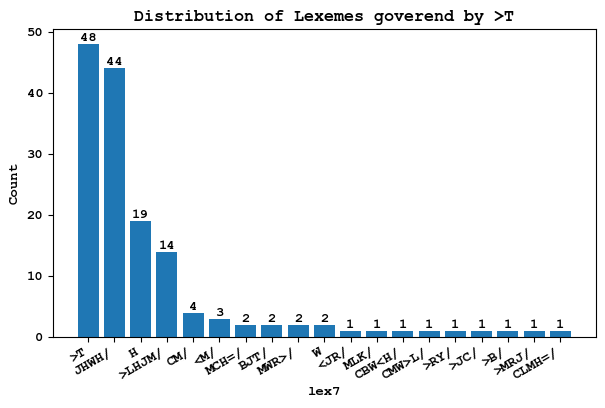

In [154]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# Styling
mpl.rcParams["font.family"] = "Courier New"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["axes.titleweight"] = "bold"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

plt.figure(figsize=(7, 4))

bars = plt.bar(lex7_counts.index.astype(str), lex7_counts.values)

plt.xlabel("lex7")
plt.ylabel("Count")
plt.title("Distribution of Lexemes goverend by >T")

# Add count labels
for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        h,
        str(int(h)),
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=30, ha="right")

# Save outputs
plt.savefig("fig08_lex7_distribution.pdf", bbox_inches="tight")
plt.savefig("fig08_lex7_distribution.png", dpi=600, bbox_inches="tight")

plt.show()


## Jara + Direct Object wo ET

In [155]:
FearValenceDO1 = '''
verse verse book chapter
  clause
    p1:phrase function=Pred typ
      word lex=JR>[ vs=qal vt=perf|impf|wayq|impv lex_utf8 gn nu ps sp g_cons g_lex g_word
    p2:phrase function=Objc typ
    /without/
      word lex=>T lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word
    /-/
      w1:word lex lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word


p2 =: w1

'''
FearValenceDO1  = BHS.search(FearValenceDO1)
BHS.table(FearValenceDO1, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  1.21s 18 results


n,p,verse,clause,phrase,word,phrase,word
1,Leviticus 19:3,,אִמֹּ֤ו וְאָבִיו֙ תִּירָ֔אוּ,תִּירָ֔אוּ,תִּירָ֔אוּ,אִמֹּ֤ו וְאָבִיו֙,אִמֹּ֤ו
2,Leviticus 19:30,,וּמִקְדָּשִׁ֖י תִּירָ֑אוּ,תִּירָ֑אוּ,תִּירָ֑אוּ,מִקְדָּשִׁ֖י,מִקְדָּשִׁ֖י
3,Leviticus 26:2,,וּמִקְדָּשִׁ֖י תִּירָ֑אוּ,תִּירָ֑אוּ,תִּירָ֑אוּ,מִקְדָּשִׁ֖י,מִקְדָּשִׁ֖י


In [156]:
BHS.export(FearValenceDO1, toDir='/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/', toFile='FearValDataExport_DO_woET.tsv')

In [157]:
FearValenceDO=pd.read_csv('/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/FearValDataExport_DO_woET.tsv',delimiter='\t',encoding='utf-16')
pd.set_option('display.max_columns', 50)
FearValenceDO.head(10)

,R,S1,S2,S3,NODE1,TYPE1,TEXT1,book1,chapter1,verse1,NODE2,TYPE2,TEXT2,NODE3,TYPE3,TEXT3,function3,typ3,NODE4,TYPE4,TEXT4,g_cons4,g_lex4,g_word4,gn4,...,lex_utf84,nu4,ps4,sp4,vs4,vt4,NODE5,TYPE5,TEXT5,function5,typ5,NODE6,TYPE6,TEXT6,g_cons6,g_lex6,g_word6,gn6,lex6,lex_utf86,nu6,ps6,sp6,vs6,vt6
0,1,Leviticus,19,3,1417673,verse,אִ֣ישׁ אִמֹּ֤ו וְאָבִיו֙ תִּירָ֔אוּ וְאֶת־שַׁב...,Leviticus,19,3,439829,clause,אִמֹּ֤ו וְאָבִיו֙ תִּירָ֔אוּ,688881,phrase,תִּירָ֔אוּ,Pred,VP,63851,word,תִּירָ֔אוּ,TJR>W,JR@>,T.IJR@80>W.,m,...,ירא,pl,p2,verb,qal,impf,688880,phrase,אִמֹּ֤ו וְאָבִיו֙,Objc,NP,63848,word,אִמֹּ֤ו,>MW,>IM.,>IM.O70W,f,>M/,אם,sg,NaN,subs,NaN,NaN
1,2,Leviticus,19,30,1417700,verse,אֶת־שַׁבְּתֹתַ֣י תִּשְׁמֹ֔רוּ וּמִקְדָּשִׁ֖י ת...,Leviticus,19,30,439925,clause,וּמִקְדָּשִׁ֖י תִּירָ֑אוּ,689186,phrase,תִּירָ֑אוּ,Pred,VP,64278,word,תִּירָ֑אוּ,TJR>W,JR@>,T.IJR@92>W.,m,...,ירא,pl,p2,verb,qal,impf,689185,phrase,מִקְדָּשִׁ֖י,Objc,NP,64277,word,מִקְדָּשִׁ֖י,MQDCJ,MIQ:D.@C,MIQ:D.@CI73J,m,MQDC/,מקדשׁ,sg,NaN,subs,NaN,NaN
2,3,Leviticus,26,2,1417915,verse,אֶת־שַׁבְּתֹתַ֣י תִּשְׁמֹ֔רוּ וּמִקְדָּשִׁ֖י ת...,Leviticus,26,2,440669,clause,וּמִקְדָּשִׁ֖י תִּירָ֑אוּ,691449,phrase,תִּירָ֑אוּ,Pred,VP,68178,word,תִּירָ֑אוּ,TJR>W,JR@>,T.IJR@92>W.,m,...,ירא,pl,p2,verb,qal,impf,691448,phrase,מִקְדָּשִׁ֖י,Objc,NP,68177,word,מִקְדָּשִׁ֖י,MQDCJ,MIQ:D.@C,MIQ:D.@CI73J,m,MQDC/,מקדשׁ,sg,NaN,subs,NaN,NaN
3,4,Deuteronomy,25,18,1419955,verse,אֲשֶׁ֨ר קָֽרְךָ֜ בַּדֶּ֗רֶךְ וַיְזַנֵּ֤ב בְּךָ...,Deuteronomium,25,18,447594,clause,וְלֹ֥א יָרֵ֖א אֱלֹהִֽים׃,712454,phrase,יָרֵ֖א,Pred,VP,107125,word,יָרֵ֖א,JR>,J@R;>,J@R;73>,m,...,ירא,sg,p3,verb,qal,perf,712455,phrase,אֱלֹהִֽים׃,Objc,NP,107126,word,אֱלֹהִֽים׃,>LHJM,>:ELOH,>:ELOHI75JM,m,>LHJM/,אלהים,pl,NaN,subs,NaN,NaN
4,5,2_Kings,17,7,1424297,verse,וַיְהִ֗י כִּֽי־חָטְא֤וּ בְנֵֽי־יִשְׂרָאֵל֙ לַי...,Reges_II,17,7,467059,clause,וַיִּֽירְא֖וּ אֱלֹהִ֥ים אֲחֵרִֽים׃,770760,phrase,יִּֽירְא֖וּ,Pred,VP,205722,word,יִּֽירְא֖וּ,JJR>W,JR:>,J.I45JR:>73W.,m,...,ירא,pl,p3,verb,qal,wayq,770761,phrase,אֱלֹהִ֥ים אֲחֵרִֽים׃,Objc,NP,205723,word,אֱלֹהִ֥ים,>LHJM,>:ELOH,>:ELOHI71JM,m,>LHJM/,אלהים,pl,NaN,subs,NaN,NaN
5,6,2_Kings,17,35,1424325,verse,וַיִּכְרֹ֨ת יְהוָ֤ה אִתָּם֙ בְּרִ֔ית וַיְצַוֵּ...,Reges_II,17,35,467176,clause,לֹ֥א תִֽירְא֖וּ אֱלֹהִ֣ים אֲחֵרִ֑ים,771150,phrase,תִֽירְא֖וּ,Pred,VP,206390,word,תִֽירְא֖וּ,TJR>W,JR:>,TI45JR:>73W.,m,...,ירא,pl,p2,verb,qal,impf,771151,phrase,אֱלֹהִ֣ים אֲחֵרִ֑ים,Objc,NP,206391,word,אֱלֹהִ֣ים,>LHJM,>:ELOH,>:ELOHI74JM,m,>LHJM/,אלהים,pl,NaN,subs,NaN,NaN
6,7,2_Kings,17,37,1424327,verse,וְאֶת־הַחֻקִּ֨ים וְאֶת־הַמִּשְׁפָּטִ֜ים וְהַתּ...,Reges_II,17,37,467188,clause,וְלֹ֥א תִֽירְא֖וּ אֱלֹהִ֥ים אֲחֵרִֽים׃,771188,phrase,תִֽירְא֖וּ,Pred,VP,206454,word,תִֽירְא֖וּ,TJR>W,JR:>,TI45JR:>73W.,m,...,ירא,pl,p2,verb,qal,impf,771189,phrase,אֱלֹהִ֥ים אֲחֵרִֽים׃,Objc,NP,206455,word,אֱלֹהִ֥ים,>LHJM,>:ELOH,>:ELOHI71JM,m,>LHJM/,אלהים,pl,NaN,subs,NaN,NaN
7,8,2_Kings,17,38,1424328,verse,וְהַבְּרִ֛ית אֲשֶׁר־כָּרַ֥תִּי אִתְּכֶ֖ם לֹ֣א ...,Reges_II,17,38,467191,clause,וְלֹ֥א תִֽירְא֖וּ אֱלֹהִ֥ים אֲחֵרִֽים׃,771199,phrase,תִֽירְא֖וּ,Pred,VP,206467,word,תִֽירְא֖וּ,TJR>W,JR:>,TI45JR:>73W.,m,...,ירא,pl,p2,verb,qal,impf,771200,phrase,אֱלֹהִ֥ים אֲחֵרִֽים׃,Objc,NP,206468,word,אֱלֹהִ֥ים,>LHJM,>:ELOH,>:ELOHI71JM,m,>LHJM/,אלהים,pl,NaN,subs,NaN,NaN
8,9,Isaiah,51,7,1425585,verse,שִׁמְע֤וּ אֵלַי֙ יֹ֣דְעֵי צֶ֔דֶק עַ֖ם תֹּורָתִ...,Jesaia,51,7,472552,clause,אַל־תִּֽירְאוּ֙ חֶרְפַּ֣ת אֱנֹ֔ושׁ,785854,phrase,תִּֽירְאוּ֙,Pred,VP,229985,word,תִּֽירְאוּ֙,TJR>W,JR:>,T.I45JR:>W.03,m,...,ירא,pl,p2,verb,qal,impf,785855,phrase,חֶרְפַּ֣ת אֱנֹ֔ושׁ,Objc,NP,229986,word,חֶרְפַּ֣ת,XRPT,XER:P.,XER:P.A74T,f,XRPH/,חרפה,sg,NaN,subs,NaN,NaN
9,10,Ezekiel,11,8,1427413,verse,חֶ֖רֶב יְרֵאתֶ֑ם וְחֶ֨רֶב֙ אָבִ֣יא עֲלֵיכֶ֔ם נ...,Ezechiel,11,8,480961,clause,חֶ֖רֶב יְרֵאתֶ֑ם,809431,phrase,יְרֵאתֶ֑ם,Pred,VP,268989,word,יְרֵאתֶ֑ם,JR>TM,J:R;>,J:R;>TE92M,m,...,ירא,pl,p2,verb,qal,perf,809430,phrase,חֶ֖רֶב,Objc,NP,268988,word,חֶ֖רֶב,XRB,XEREB,XE73REB,f,XRB/,חרב,sg,NaN,subs,NaN,NaN


In [158]:
FearValenceDO2 = '''
verse verse book chapter
  clause
    p1:phrase function=PreO typ
      word lex=JR>[ vs=qal vt=perf|impf|wayq|impv lex_utf8 gn nu ps sp g_cons g_lex g_word



'''
FearValenceDO2  = BHS.search(FearValenceDO2)
BHS.table(FearValenceDO2, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  0.40s 12 results


n,p,verse,clause,phrase,word
1,Numbers 14:9,,אַל־תִּירָאֻֽם׃,תִּירָאֻֽם׃,תִּירָאֻֽם׃
2,Deuteronomy 3:22,,לֹ֖א תִּֽירָא֑וּם,תִּֽירָא֑וּם,תִּֽירָא֑וּם
3,1_Kings 8:40,,לְמַ֨עַן֙ יִֽרָא֔וּךָ כָּל־הַ֨יָּמִ֔ים,יִֽרָא֔וּךָ,יִֽרָא֔וּךָ


In [159]:
BHS.export(FearValenceDO2, toDir='/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/', toFile='FearValDataExport_PreO.tsv')

In [160]:
FearValencePreO=pd.read_csv('/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/FearValDataExport_PreO.tsv',delimiter='\t',encoding='utf-16')
pd.set_option('display.max_columns', 50)
FearValencePreO.head(10)

,R,S1,S2,S3,NODE1,TYPE1,TEXT1,book1,chapter1,verse1,NODE2,TYPE2,TEXT2,NODE3,TYPE3,TEXT3,function3,typ3,NODE4,TYPE4,TEXT4,g_cons4,g_lex4,g_word4,gn4,lex4,lex_utf84,nu4,ps4,sp4,vs4,vt4
0,1,Numbers,14,9,1418506,verse,אַ֣ךְ בַּֽיהוָה֮ אַל־תִּמְרֹדוּ֒ וְאַתֶּ֗ם אַל...,Numeri,14,9,442392,clause,אַל־תִּירָאֻֽם׃,696617,phrase,תִּירָאֻֽם׃,PreO,VP,78597,word,תִּירָאֻֽם׃,TJR>M,JR@>,T.IJR@>U75M,m,JR>[,ירא,pl,p2,verb,qal,impf
1,2,Deuteronomy,3,22,1419387,verse,לֹ֖א תִּֽירָא֑וּם כִּ֚י יְהוָ֣ה אֱלֹֽהֵיכֶ֔ם ה...,Deuteronomium,3,22,445283,clause,לֹ֖א תִּֽירָא֑וּם,705411,phrase,תִּֽירָא֑וּם,PreO,VP,95000,word,תִּֽירָא֑וּם,TJR>WM,JR@>,T.I45JR@>92W.M,m,JR>[,ירא,pl,p2,verb,qal,impf
2,3,1_Kings,8,40,1423331,verse,לְמַ֨עַן֙ יִֽרָא֔וּךָ כָּל־הַ֨יָּמִ֔ים אֲשֶׁר־...,Reges_I,8,40,462381,clause,לְמַ֨עַן֙ יִֽרָא֔וּךָ כָּל־הַ֨יָּמִ֔ים,757075,phrase,יִֽרָא֔וּךָ,PreO,VP,183004,word,יִֽרָא֔וּךָ,JR>WK,R@>,JI45R@>80W.K@,m,JR>[,ירא,pl,p3,verb,qal,impf
3,4,Isaiah,25,3,1425026,verse,עַל־כֵּ֖ן יְכַבְּד֣וּךָ עַם־עָ֑ז קִרְיַ֛ת גֹּו...,Jesaia,25,3,469945,clause,קִרְיַ֛ת גֹּויִ֥ם עָרִיצִ֖ים יִירָאֽוּךָ׃,779038,phrase,יִירָאֽוּךָ׃,PreO,VP,220100,word,יִירָאֽוּךָ׃,JJR>WK,JR@>,JIJR@>75W.K@,m,JR>[,ירא,pl,p3,verb,qal,impf
4,5,Jeremiah,10,7,1426112,verse,מִ֣י לֹ֤א יִֽרָאֲךָ֙ מֶ֣לֶךְ הַגֹּויִ֔ם כִּ֥י ...,Jeremia,10,7,475070,clause,מִ֣י לֹ֤א יִֽרָאֲךָ֙,792664,phrase,יִֽרָאֲךָ֙,PreO,VP,240005,word,יִֽרָאֲךָ֙,JR>K,R@>,JI45R@>:AK@03,m,JR>[,ירא,sg,p3,verb,qal,impf
5,6,Malachi,2,5,1429501,verse,בְּרִיתִ֣י׀ הָיְתָ֣ה אִתֹּ֗ו הַֽחַיִּים֙ וְהַ֨...,Maleachi,2,5,490060,clause,וַיִּֽירָאֵ֑נִי,834865,phrase,יִּֽירָאֵ֑נִי,PreO,VP,309875,word,יִּֽירָאֵ֑נִי,JJR>NJ,JR@>,J.I45JR@>;92NIJ,m,JR>[,ירא,sg,p3,verb,qal,wayq
6,7,Malachi,3,5,1429518,verse,וְקָרַבְתִּ֣י אֲלֵיכֶם֮ לַמִּשְׁפָּט֒ וְהָיִ֣י...,Maleachi,3,5,490144,clause,וְלֹ֣א יְרֵא֔וּנִי,835117,phrase,יְרֵא֔וּנִי,PreO,VP,310278,word,יְרֵא֔וּנִי,JR>WNJ,J:R;>,J:R;>80W.NIJ,unknown,JR>[,ירא,pl,p3,verb,qal,perf
7,8,Psalms,72,5,1430654,verse,יִֽירָא֥וּךָ עִם־שָׁ֑מֶשׁ וְלִפְנֵ֥י יָ֝רֵ֗חַ ...,Psalmi,72,5,493723,clause,יִֽירָא֥וּךָ עִם־שָׁ֑מֶשׁ וְלִפְנֵ֥י יָ֝רֵ֗חַ ...,843694,phrase,יִֽירָא֥וּךָ,PreO,VP,322351,word,יִֽירָא֥וּךָ,JJR>WK,JR@>,JI45JR@>71W.K@,m,JR>[,ירא,pl,p3,verb,qal,impf
8,9,Psalms,119,63,1431623,verse,חָבֵ֣ר אָ֭נִי לְכָל־אֲשֶׁ֣ר יְרֵא֑וּךָ וּ֝לְשׁ...,Psalmi,119,63,496311,clause,אֲשֶׁ֣ר יְרֵא֑וּךָ,850161,phrase,יְרֵא֑וּךָ,PreO,VP,331790,word,יְרֵא֑וּךָ,JR>WK,J:R;>,J:R;>92W.K@,unknown,JR>[,ירא,pl,p3,verb,qal,perf
9,10,Job,9,35,1432281,verse,אַֽ֭דַבְּרָה וְלֹ֣א אִירָאֶ֑נּוּ כִּ֥י לֹא־כֵ֥...,Iob,9,35,498186,clause,וְלֹ֣א אִירָאֶ֑נּוּ,854986,phrase,אִירָאֶ֑נּוּ,PreO,VP,338580,word,אִירָאֶ֑נּוּ,>JR>NW,JR@>,>IJR@>E92N.W.,unknown,JR>[,ירא,sg,p1,verb,qal,impf


In [161]:
lex7_counts = FearValenceDO["lex4"].value_counts()
lex7_counts

lex4
JR>[    18
Name: count, dtype: int64

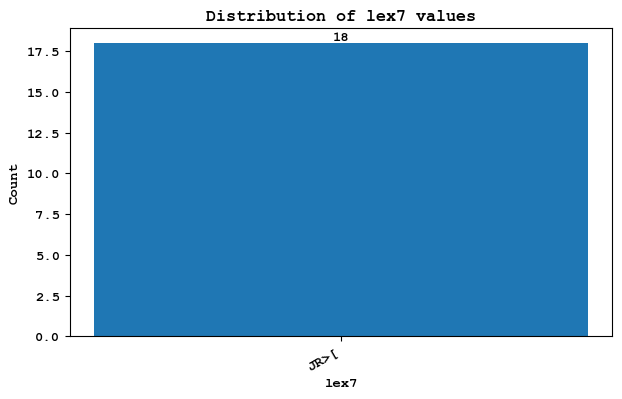

In [162]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# Styling
mpl.rcParams["font.family"] = "Courier New"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["axes.titleweight"] = "bold"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

plt.figure(figsize=(7, 4))

bars = plt.bar(lex7_counts.index.astype(str), lex7_counts.values)

plt.xlabel("lex7")
plt.ylabel("Count")
plt.title("Distribution of lex7 values")

# Add count labels
for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        h,
        str(int(h)),
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=30, ha="right")

# Save outputs
plt.savefig("fig07_lex7_distribution.pdf", bbox_inches="tight")
plt.savefig("fig07_lex7_distribution.png", dpi=600, bbox_inches="tight")

plt.show()


## Jara + >T

In [163]:
FearValenceET1 = '''
verse verse book chapter
  clause
    p1:phrase function typ
      word lex=JR>[ vs=qal vt=perf|impf|wayq|impv lex_utf8 gn nu ps sp g_cons g_lex g_word
    p2:phrase function typ=PP
      w1:word lex=>T lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word
      w2:word lex lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word


p2 =: w1
w1 <: w2

'''
FearValenceET1  = BHS.search(FearValenceET1)
BHS.table(FearValenceET1, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  1.64s 36 results


n,p,verse,clause,phrase,word,phrase,word,word
1,Exodus 1:17,,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,תִּירֶ֤אןָ,תִּירֶ֤אןָ,אֶת־הָ֣אֱלֹהִ֔ים,אֶת־,הָ֣
2,Exodus 1:21,,כִּֽי־יָֽרְא֥וּ הַֽמְיַלְּדֹ֖ת אֶת־הָאֱלֹהִ֑ים,יָֽרְא֥וּ,יָֽרְא֥וּ,אֶת־הָאֱלֹהִ֑ים,אֶת־,הָ
3,Exodus 14:31,,וַיִּֽירְא֥וּ הָעָ֖ם אֶת־יְהוָ֑ה,יִּֽירְא֥וּ,יִּֽירְא֥וּ,אֶת־יְהוָ֑ה,אֶת־,יְהוָ֑ה


In [164]:
FearValenceET2 = '''
verse verse book chapter
  clause
    p1:phrase function typ
      word lex=JR>[ vs=qal vt=perf|impf|wayq|impv lex_utf8 gn nu ps sp g_cons g_lex g_word
    p2:phrase function typ=PP
      w1:word lex=>T lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word
      w2:word lex lex_utf8 vs vt gn nu ps sp g_cons g_lex g_word


p2 =: w1

'''
FearValenceET2  = BHS.search(FearValenceET2)
BHS.table(FearValenceET2, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  1.59s 113 results


n,p,verse,clause,phrase,word,phrase,word,word
1,Exodus 1:17,,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,תִּירֶ֤אןָ,תִּירֶ֤אןָ,אֶת־הָ֣אֱלֹהִ֔ים,אֶת־,אֶת־
2,Exodus 1:17,,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,תִּירֶ֤אןָ,תִּירֶ֤אןָ,אֶת־הָ֣אֱלֹהִ֔ים,אֶת־,הָ֣
3,Exodus 1:17,,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,תִּירֶ֤אןָ,תִּירֶ֤אןָ,אֶת־הָ֣אֱלֹהִ֔ים,אֶת־,אֱלֹהִ֔ים


In [165]:
BHS.export(FearValenceET1+FearValenceET2, toDir='/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/', toFile='FearValDataExport_ET.tsv')

In [166]:
FearValenceET=pd.read_csv('/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/FearValDataExport_ET.tsv',delimiter='\t',encoding='utf-16')
pd.set_option('display.max_columns', 50)
FearValenceET.head(10)

,R,S1,S2,S3,NODE1,TYPE1,TEXT1,book1,chapter1,verse1,NODE2,TYPE2,TEXT2,NODE3,TYPE3,TEXT3,function3,typ3,NODE4,TYPE4,TEXT4,g_cons4,g_lex4,g_word4,gn4,...,g_cons6,g_lex6,g_word6,gn6,lex6,lex_utf86,nu6,ps6,sp6,vs6,vt6,NODE7,TYPE7,TEXT7,g_cons7,g_lex7,g_word7,gn7,lex7,lex_utf87,nu7,ps7,sp7,vs7,vt7
0,1,Exodus,1,17,1415938,verse,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים ו...,Exodus,1,17,433593,clause,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,669693,phrase,תִּירֶ֤אןָ,Pred,VP,29000,word,תִּירֶ֤אןָ,TJR>N,JRE>,T.IJRE70>N@,f,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,29004,word,הָ֣,H,H@-,H@74-,NaN,H,ה,NaN,NaN,art,NaN,NaN
1,2,Exodus,1,21,1415942,verse,וַיְהִ֕י כִּֽי־יָֽרְא֥וּ הַֽמְיַלְּדֹ֖ת אֶת־הָ...,Exodus,1,21,433610,clause,כִּֽי־יָֽרְא֥וּ הַֽמְיַלְּדֹ֖ת אֶת־הָאֱלֹהִ֑ים,669749,phrase,יָֽרְא֥וּ,Pred,VP,29083,word,יָֽרְא֥וּ,JR>W,J@R:>,J@45R:>71W.,unknown,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,29087,word,הָ,H,H@-,H@-,NaN,H,ה,NaN,NaN,art,NaN,NaN
2,3,Exodus,14,31,1416309,verse,וַיַּ֨רְא יִשְׂרָאֵ֜ל אֶת־הַיָּ֣ד הַגְּדֹלָ֗ה ...,Exodus,14,31,435129,clause,וַיִּֽירְא֥וּ הָעָ֖ם אֶת־יְהוָ֑ה,674410,phrase,יִּֽירְא֥וּ,Pred,VP,36902,word,יִּֽירְא֥וּ,JJR>W,JR:>,J.I45JR:>71W.,m,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,36906,word,יְהוָ֑ה,JHWH,J:HW@H,J:HW@92H,m,JHWH/,יהוה,sg,NaN,nmpr,NaN,NaN
3,4,Numbers,14,9,1418506,verse,אַ֣ךְ בַּֽיהוָה֮ אַל־תִּמְרֹדוּ֒ וְאַתֶּ֗ם אַל...,Numeri,14,9,442388,clause,וְאַתֶּ֗ם אַל־תִּֽירְאוּ֙ אֶת־עַ֣ם הָאָ֔רֶץ,696605,phrase,תִּֽירְאוּ֙,Pred,VP,78581,word,תִּֽירְאוּ֙,TJR>W,JR:>,T.I45JR:>W.03,m,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,78583,word,עַ֣ם,<M,<AM,<A74M,m,<M/,עם,sg,NaN,subs,NaN,NaN
4,5,Deuteronomy,6,2,1419478,verse,לְמַ֨עַן תִּירָ֜א אֶת־יְהוָ֣ה אֱלֹהֶ֗יךָ לִ֠שׁ...,Deuteronomium,6,2,445647,clause,לְמַ֨עַן תִּירָ֜א אֶת־יְהוָ֣ה אֱלֹהֶ֗יךָ אַתָּ...,706500,phrase,תִּירָ֜א,Pred,VP,96992,word,תִּירָ֜א,TJR>,JR@>,T.IJR@61>,m,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,96994,word,יְהוָ֣ה,JHWH,J:HW@H,J:HW@74H,m,JHWH/,יהוה,sg,NaN,nmpr,NaN,NaN
5,6,Deuteronomy,6,13,1419489,verse,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ תִּירָ֖א וְאֹתֹ֣ו תַעֲב...,Deuteronomium,6,13,445689,clause,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ תִּירָ֖א,706614,phrase,תִּירָ֖א,Pred,VP,97194,word,תִּירָ֖א,TJR>,JR@>,T.IJR@73>,m,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,97192,word,יְהוָ֧ה,JHWH,J:HW@H,J:HW@94H,m,JHWH/,יהוה,sg,NaN,nmpr,NaN,NaN
6,7,Deuteronomy,10,20,1419596,verse,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ תִּירָ֖א אֹתֹ֣ו תַעֲבֹ֑...,Deuteronomium,10,20,446142,clause,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ תִּירָ֖א,707957,phrase,תִּירָ֖א,Pred,VP,99544,word,תִּירָ֖א,TJR>,JR@>,T.IJR@73>,m,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,99542,word,יְהוָ֧ה,JHWH,J:HW@H,J:HW@94H,m,JHWH/,יהוה,sg,NaN,nmpr,NaN,NaN
7,8,Deuteronomy,31,12,1420130,verse,הַקְהֵ֣ל אֶת־הָעָ֗ם הָֽאֲנָשִׁ֤ים וְהַנָּשִׁים...,Deuteronomium,31,12,448294,clause,וְיָֽרְאוּ֙ אֶת־יְהוָ֣ה אֱלֹֽהֵיכֶ֔ם,714529,phrase,יָֽרְאוּ֙,Pred,VP,110943,word,יָֽרְאוּ֙,JR>W,J@R:>,J@45R:>W.03,unknown,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,110945,word,יְהוָ֣ה,JHWH,J:HW@H,J:HW@74H,m,JHWH/,יהוה,sg,NaN,nmpr,NaN,NaN
8,9,Joshua,4,14,1420314,verse,בַּיֹּ֣ום הַה֗וּא גִּדַּ֤ל יְהוָה֙ אֶת־יְהֹושׁ...,Josua,4,14,449081,clause,כַּאֲשֶׁ֛ר יָרְא֥וּ אֶת־מֹשֶׁ֖ה כָּל־יְמֵ֥י חַ...,716783,phrase,יָרְא֥וּ,Pred,VP,114739,word,יָרְא֥וּ,JR>W,J@R:>,J@R:>71W.,unknown,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,114741,word,מֹשֶׁ֖ה,MCH,MOCEH,MOCE73H,m,MCH=/,משׁה,sg,NaN,nmpr,NaN,NaN
9,10,Joshua,4,24,1420324,verse,לְ֠מַעַן דַּ֜עַת כָּל־עַמֵּ֤י הָאָ֨רֶץ֙ אֶת־יַ...,Josua,4,24,449113,clause,לְמַ֧עַן יְרָאתֶ֛ם אֶת־יְהוָ֥ה אֱלֹהֵיכֶ֖ם כָּ...,716876,phrase,יְרָאתֶ֛ם,Pred,VP,114931,word,יְרָאתֶ֛ם,JR>TM,J:R@>,J:R@>TE91M,m,...,>T,>ET,>ET,NaN,>T,את,NaN,NaN,prep,NaN,NaN,114933,word,יְהוָ֥ה,JHWH,J:HW@H,J:HW@71H,m,JHWH/,יהוה,sg,NaN,nmpr,NaN,NaN


In [167]:
lex7_counts = FearValenceET["lex7"].value_counts()
lex7_counts

lex7
>T        48
JHWH/     44
H         19
>LHJM/    14
CM/        4
<M/        3
MCH=/      2
BJT/       2
MWR>/      2
W          2
<JR/       1
MLK/       1
CBW<H/     1
CMW>L/     1
>RY/       1
>JC/       1
>B/        1
>MRJ/      1
CLMH=/     1
Name: count, dtype: int64

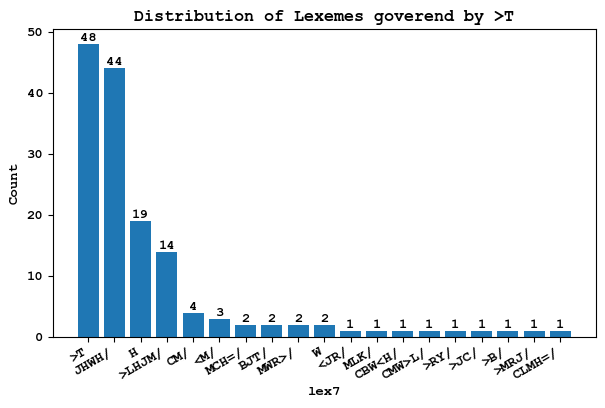

In [168]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# Styling
mpl.rcParams["font.family"] = "Courier New"
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["axes.titleweight"] = "bold"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

plt.figure(figsize=(7, 4))

bars = plt.bar(lex7_counts.index.astype(str), lex7_counts.values)

plt.xlabel("lex7")
plt.ylabel("Count")
plt.title("Distribution of Lexemes goverend by >T")

# Add count labels
for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        h,
        str(int(h)),
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=30, ha="right")

# Save outputs
plt.savefig("fig08_lex7_distribution.pdf", bbox_inches="tight")
plt.savefig("fig08_lex7_distribution.png", dpi=600, bbox_inches="tight")

plt.show()


In [169]:
FearVal1 = '''
clause
  phrase function
    word lex=JR>[ vs=qal
'''
FearVal1  = BHS.search(FearVal1)
BHS.table(FearVal1, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  0.16s 282 results


n,p,clause,phrase,word
1,Genesis 3:10,וָאִירָ֛א,אִירָ֛א,אִירָ֛א
2,Genesis 15:1,אַל־תִּירָ֣א,תִּירָ֣א,תִּירָ֣א
3,Genesis 18:15,כִּ֣י׀ יָרֵ֑אָה,יָרֵ֑אָה,יָרֵ֑אָה


In [170]:
FearValDataExport0 = '''
clause
  phrase function*
    word lex=JR>[ vs=qal vt=perf|impf|wayq|impv
'''
FearValDataExport0  = BHS.search(FearValDataExport0)
BHS.table(FearValDataExport0, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  0.18s 248 results


n,p,clause,phrase,word
1,Genesis 3:10,וָאִירָ֛א,אִירָ֛א,אִירָ֛א
2,Genesis 15:1,אַל־תִּירָ֣א,תִּירָ֣א,תִּירָ֣א
3,Genesis 18:15,כִּ֣י׀ יָרֵ֑אָה,יָרֵ֑אָה,יָרֵ֑אָה


In [171]:
FearValDataExport0 = '''
clause
  phrase function=Pred|PreO|
    word lex=JR>[ vs=qal vt=perf|impf|wayq|impv
'''
FearValDataExport0  = BHS.search(FearValDataExport0)
BHS.table(FearValDataExport0, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  0.18s 248 results


n,p,clause,phrase,word
1,Genesis 3:10,וָאִירָ֛א,אִירָ֛א,אִירָ֛א
2,Genesis 15:1,אַל־תִּירָ֣א,תִּירָ֣א,תִּירָ֣א
3,Genesis 18:15,כִּ֣י׀ יָרֵ֑אָה,יָרֵ֑אָה,יָרֵ֑אָה


In [172]:
BHS.export(FearValDataExport0, toDir='/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/', toFile='FearValDataExport_FiniteVerbs.tsv')

In [173]:
FearValDataExport1 = '''
clause
/without/
  phrase function=Objc|Cmpl
/-/
  phrase function=Pred|PreO|PreS
    word lex=JR>[ vs=qal vt=perf|impf|wayq|impv
'''
FearValDataExport1  = BHS.search(FearValDataExport1)
BHS.table(FearValDataExport1, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  0.30s 132 results


n,p,clause,phrase,word
1,Genesis 3:10,וָאִירָ֛א,אִירָ֛א,אִירָ֛א
2,Genesis 15:1,אַל־תִּירָ֣א,תִּירָ֣א,תִּירָ֣א
3,Genesis 18:15,כִּ֣י׀ יָרֵ֑אָה,יָרֵ֑אָה,יָרֵ֑אָה


In [174]:
BHS.export(FearValDataExport1, toDir='/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/', toFile='FearValDataExport_wo_ObjcCmpl.tsv')

In [175]:
FearValDataExport_wo_ObjcCmpl=pd.read_csv('/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/FearValDataExport_wo_ObjcCmpl.tsv',delimiter='\t',encoding='utf-16')
pd.set_option('display.max_columns', 50)
FearValDataExport_wo_ObjcCmpl.head(10)

,R,S1,S2,S3,NODE1,TYPE1,TEXT1,NODE2,TYPE2,TEXT2,function2,NODE3,TYPE3,TEXT3,lex3,vs3,vt3
0,1,Genesis,3,10,427818,clause,וָאִירָ֛א,652349,phrase,אִירָ֛א,Pred,1364,word,אִירָ֛א,JR>[,qal,wayq
1,2,Genesis,15,1,428731,clause,אַל־תִּירָ֣א,655223,phrase,תִּירָ֣א,Pred,6686,word,תִּירָ֣א,JR>[,qal,impf
2,3,Genesis,18,15,429019,clause,כִּ֣י׀ יָרֵ֑אָה,656102,phrase,יָרֵ֑אָה,Pred,8069,word,יָרֵ֑אָה,JR>[,qal,perf
3,4,Genesis,19,30,429249,clause,כִּ֥י יָרֵ֖א,656771,phrase,יָרֵ֖א,Pred,9075,word,יָרֵ֖א,JR>[,qal,perf
4,5,Genesis,20,8,429326,clause,וַיִּֽירְא֥וּ הָאֲנָשִׁ֖ים מְאֹֽד׃,657007,phrase,יִּֽירְא֥וּ,Pred,9421,word,יִּֽירְא֥וּ,JR>[,qal,wayq
5,6,Genesis,21,17,429431,clause,אַל־תִּ֣ירְאִ֔י,657345,phrase,תִּ֣ירְאִ֔י,Pred,9926,word,תִּ֣ירְאִ֔י,JR>[,qal,impf
6,7,Genesis,26,7,430103,clause,כִּ֤י יָרֵא֙,659322,phrase,יָרֵא֙,Pred,13109,word,יָרֵא֙,JR>[,qal,perf
7,8,Genesis,26,24,430174,clause,אַל־תִּירָא֙,659548,phrase,תִּירָא֙,Pred,13432,word,תִּירָא֙,JR>[,qal,impf
8,9,Genesis,28,17,430516,clause,וַיִּירָא֙,660531,phrase,יִּירָא֙,Pred,14827,word,יִּירָא֙,JR>[,qal,wayq
9,10,Genesis,31,31,430982,clause,כִּ֣י יָרֵ֔אתִי,661981,phrase,יָרֵ֔אתִי,Pred,16943,word,יָרֵ֔אתִי,JR>[,qal,perf


In [176]:
FearValDataExport_wo_ObjcCmpl.shape


(132, 17)

In [177]:
FearValDataExport2 = '''
clause
  phrase function=Pred|PreO
    word lex=JR>[ vs=qal vt=perf|impf|wayq|impv
  phrase function=Cmpl
    word lex*
'''
FearValDataExport2  = BHS.search(FearValDataExport2)
BHS.table(FearValDataExport2, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  0.45s 129 results


n,p,clause,phrase,word,phrase,word
1,Exodus 9:30,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,תִּֽירְא֔וּן,תִּֽירְא֔וּן,מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,מִ
2,Exodus 9:30,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,תִּֽירְא֔וּן,תִּֽירְא֔וּן,מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,פְּנֵ֖י
3,Exodus 9:30,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,תִּֽירְא֔וּן,תִּֽירְא֔וּן,מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,יְהוָ֥ה


In [178]:
BHS.export(FearValDataExport2, toDir='/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/1200_AUS-research/Fabric-TEXT/course_TF-Workshop/data_export/ValenceBookChapter/', toFile='FearValDataExport_w_ObjcCmpl.tsv')

In [179]:
FearVal1 = '''
clause
    phrase function=Pred
        word lex=JR>[
    phrase function=Cmpl|Objc
'''
FearVal1  = BHS.search(FearVal1)
BHS.table(FearVal1, start=1, end=3, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  0.26s 134 results


n,p,clause,phrase,word,phrase
1,Exodus 1:17,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,תִּירֶ֤אןָ,תִּירֶ֤אןָ,אֶת־הָ֣אֱלֹהִ֔ים
2,Exodus 1:21,כִּֽי־יָֽרְא֥וּ הַֽמְיַלְּדֹ֖ת אֶת־הָאֱלֹהִ֑ים,יָֽרְא֥וּ,יָֽרְא֥וּ,אֶת־הָאֱלֹהִ֑ים
3,Exodus 9:30,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,תִּֽירְא֔וּן,תִּֽירְא֔וּן,מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃


Interestingly, but perhaps not surprising, we are finding JHWH|>LHJM in the complement position. So lets further specify the query and just search for complement phrases that have the divine name contained.

In [180]:
FearVal2 = '''
clause
    phrase function=Pred
        word lex=JR>[
    phrase function=Cmpl|Objc
        word lex=JHWH/|>L/|>LHJM/
'''
FearVal2  = BHS.search(FearVal2)
BHS.table(FearVal2, start=1, end=5, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 4:'magenta'})

  0.37s 65 results


n,p,clause,phrase,word,phrase,word
1,Exodus 1:17,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,תִּירֶ֤אןָ,תִּירֶ֤אןָ,אֶת־הָ֣אֱלֹהִ֔ים,אֱלֹהִ֔ים
2,Exodus 1:21,כִּֽי־יָֽרְא֥וּ הַֽמְיַלְּדֹ֖ת אֶת־הָאֱלֹהִ֑ים,יָֽרְא֥וּ,יָֽרְא֥וּ,אֶת־הָאֱלֹהִ֑ים,אֱלֹהִ֑ים
3,Exodus 9:30,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,תִּֽירְא֔וּן,תִּֽירְא֔וּן,מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,יְהוָ֥ה
4,Exodus 9:30,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,תִּֽירְא֔וּן,תִּֽירְא֔וּן,מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,אֱלֹהִֽים׃
5,Exodus 14:31,וַיִּֽירְא֥וּ הָעָ֖ם אֶת־יְהוָ֑ה,יִּֽירְא֥וּ,יִּֽירְא֥וּ,אֶת־יְהוָ֑ה,יְהוָ֑ה


It seems that the preposition >T and MN are usually at the head of the complement phrase. So lets search more specifically.

In [181]:
FearVal3 = '''
clause
    phrase function=Pred
        word lex=JR>[
    phrase function=Cmpl|Objc
        =: word sp=prep lex*
        <: word lex=JHWH/|>L/|>LHJM/
        
'''
FearVal3  = BHS.search(FearVal3)
BHS.table(FearVal3, start=1, end=34, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 5:'magenta', 6:'cyan'})

  0.55s 34 results


n,p,clause,phrase,word,phrase,word,word
1,Exodus 14:31,וַיִּֽירְא֥וּ הָעָ֖ם אֶת־יְהוָ֑ה,יִּֽירְא֥וּ,יִּֽירְא֥וּ,אֶת־יְהוָ֑ה,אֶת־,יְהוָ֑ה
2,Leviticus 19:14,וְיָרֵ֥אתָ מֵּאֱלֹהֶ֖יךָ,יָרֵ֥אתָ,יָרֵ֥אתָ,מֵּאֱלֹהֶ֖יךָ,מֵּ,אֱלֹהֶ֖יךָ
3,Leviticus 19:32,וְיָרֵ֥אתָ מֵּאֱלֹהֶ֖יךָ,יָרֵ֥אתָ,יָרֵ֥אתָ,מֵּאֱלֹהֶ֖יךָ,מֵּ,אֱלֹהֶ֖יךָ
4,Leviticus 25:17,וְיָרֵ֖אתָ מֵֽאֱלֹהֶ֑יךָ,יָרֵ֖אתָ,יָרֵ֖אתָ,מֵֽאֱלֹהֶ֑יךָ,מֵֽ,אֱלֹהֶ֑יךָ
5,Leviticus 25:36,וְיָרֵ֖אתָ מֵֽאֱלֹהֶ֑יךָ,יָרֵ֖אתָ,יָרֵ֖אתָ,מֵֽאֱלֹהֶ֑יךָ,מֵֽ,אֱלֹהֶ֑יךָ
6,Leviticus 25:43,וְיָרֵ֖אתָ מֵאֱלֹהֶֽיךָ׃,יָרֵ֖אתָ,יָרֵ֖אתָ,מֵאֱלֹהֶֽיךָ׃,מֵ,אֱלֹהֶֽיךָ׃
7,Deuteronomy 6:2,לְמַ֨עַן תִּירָ֜א אֶת־יְהוָ֣ה אֱלֹהֶ֗יךָ אַתָּה֙ וּבִנְךָ֣ וּבֶן־בִּנְךָ֔ כֹּ֖ל יְמֵ֣י חַיֶּ֑יךָ,תִּירָ֜א,תִּירָ֜א,אֶת־יְהוָ֣ה אֱלֹהֶ֗יךָ,אֶת־,יְהוָ֣ה
8,Deuteronomy 6:13,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ תִּירָ֖א,תִּירָ֖א,תִּירָ֖א,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ,אֶת־,יְהוָ֧ה
9,Deuteronomy 6:24,לְיִרְאָ֖ה אֶת־יְהוָ֣ה אֱלֹהֵ֑ינוּ,לְיִרְאָ֖ה,יִרְאָ֖ה,אֶת־יְהוָ֣ה אֱלֹהֵ֑ינוּ,אֶת־,יְהוָ֣ה
10,Deuteronomy 10:12,לְ֠יִרְאָה אֶת־יְהוָ֨ה אֱלֹהֶ֜יךָ,לְ֠יִרְאָה,יִרְאָה,אֶת־יְהוָ֨ה אֱלֹהֶ֜יךָ,אֶת־,יְהוָ֨ה


In [182]:
BHS.export(FearVal3, toDir='D:/OneDrive/1200_AUS-research/Fabric-TEXT', toFile='FearVal3.tsv')

In [183]:
FearVal3=pd.read_csv('D:/OneDrive/1200_AUS-research/Fabric-TEXT/FearVal3.tsv',delimiter='\t',encoding='utf-16')
pd.set_option('display.max_columns', 50)
FearVal3.head(1)

,R,S1,S2,S3,NODE1,TYPE1,TEXT1,NODE2,TYPE2,TEXT2,function2,NODE3,TYPE3,TEXT3,lex3,NODE4,TYPE4,TEXT4,function4,NODE5,TYPE5,TEXT5,lex5,sp5,NODE6,TYPE6,TEXT6,lex6
0,1,Exodus,14,31,435129,clause,וַיִּֽירְא֥וּ הָעָ֖ם אֶת־יְהוָ֑ה,674410,phrase,יִּֽירְא֥וּ,Pred,36902,word,יִּֽירְא֥וּ,JR>[,674412,phrase,אֶת־יְהוָ֑ה,Objc,36905,word,אֶת־,>T,prep,36906,word,יְהוָ֑ה,JHWH/


In [184]:
FearVal3["lex5"].value_counts()

lex5
>T    28
MN     6
Name: count, dtype: int64

We conclude that in the majority of cases the divine name is preceded by the object marker >T. Only in a minority by the preposition MN.

### Task 1:
1. Search for only those cases where >T precedes the divine name.
2. Study the first 10 occurences of that particular valence and suggest a particular meaning for ירא.

## DObj

In [185]:
FearVal3T1 = '''
clause
    phrase function=Pred
        word lex=JR>[
    phrase function=Cmpl|Objc
        =: word sp=prep lex=>T
        <: word lex=JHWH/|>L/|>LHJM/
        
'''
FearVal3T1  = BHS.search(FearVal3T1)
BHS.table(FearVal3T1, start=1, end=10, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 5:'magenta', 6:'cyan'})

  0.48s 28 results


n,p,clause,phrase,word,phrase,word,word
1,Exodus 14:31,וַיִּֽירְא֥וּ הָעָ֖ם אֶת־יְהוָ֑ה,יִּֽירְא֥וּ,יִּֽירְא֥וּ,אֶת־יְהוָ֑ה,אֶת־,יְהוָ֑ה
2,Deuteronomy 6:2,לְמַ֨עַן תִּירָ֜א אֶת־יְהוָ֣ה אֱלֹהֶ֗יךָ אַתָּה֙ וּבִנְךָ֣ וּבֶן־בִּנְךָ֔ כֹּ֖ל יְמֵ֣י חַיֶּ֑יךָ,תִּירָ֜א,תִּירָ֜א,אֶת־יְהוָ֣ה אֱלֹהֶ֗יךָ,אֶת־,יְהוָ֣ה
3,Deuteronomy 6:13,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ תִּירָ֖א,תִּירָ֖א,תִּירָ֖א,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ,אֶת־,יְהוָ֧ה
4,Deuteronomy 6:24,לְיִרְאָ֖ה אֶת־יְהוָ֣ה אֱלֹהֵ֑ינוּ,לְיִרְאָ֖ה,יִרְאָ֖ה,אֶת־יְהוָ֣ה אֱלֹהֵ֑ינוּ,אֶת־,יְהוָ֣ה
5,Deuteronomy 10:12,לְ֠יִרְאָה אֶת־יְהוָ֨ה אֱלֹהֶ֜יךָ,לְ֠יִרְאָה,יִרְאָה,אֶת־יְהוָ֨ה אֱלֹהֶ֜יךָ,אֶת־,יְהוָ֨ה
6,Deuteronomy 10:20,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ תִּירָ֖א,תִּירָ֖א,תִּירָ֖א,אֶת־יְהוָ֧ה אֱלֹהֶ֛יךָ,אֶת־,יְהוָ֧ה
7,Deuteronomy 14:23,לְיִרְאָ֛ה אֶת־יְהוָ֥ה אֱלֹהֶ֖יךָ כָּל־הַיָּמִֽים׃,לְיִרְאָ֛ה,יִרְאָ֛ה,אֶת־יְהוָ֥ה אֱלֹהֶ֖יךָ,אֶת־,יְהוָ֥ה
8,Deuteronomy 17:19,לְיִרְאָה֙ אֶת־יְהוָ֣ה אֱלֹהָ֔יו,לְיִרְאָה֙,יִרְאָה֙,אֶת־יְהוָ֣ה אֱלֹהָ֔יו,אֶת־,יְהוָ֣ה
9,Deuteronomy 31:12,וְיָֽרְאוּ֙ אֶת־יְהוָ֣ה אֱלֹֽהֵיכֶ֔ם,יָֽרְאוּ֙,יָֽרְאוּ֙,אֶת־יְהוָ֣ה אֱלֹֽהֵיכֶ֔ם,אֶת־,יְהוָ֣ה
10,Deuteronomy 31:13,לְיִרְאָ֖ה אֶת־יְהוָ֣ה אֱלֹהֵיכֶ֑ם כָּל־הַיָּמִ֗ים,לְיִרְאָ֖ה,יִרְאָ֖ה,אֶת־יְהוָ֣ה אֱלֹהֵיכֶ֑ם,אֶת־,יְהוָ֣ה


### Task 2:
1. Search for only those cases where MN precedes the divine name.
2. Study the cases in Leviticus and suggest a particular meaning for ירא.

## MN Cmpl

In [186]:
FearVal3T2 = '''
clause
    phrase function=Pred
        word lex=JR>[
    phrase function=Cmpl|Objc
        =: word sp=prep lex=MN
        <: word lex#JHWH/|>L/|>LHJM/|PNH/
        
'''
FearVal3T2  = BHS.search(FearVal3T2)
BHS.table(FearVal3T2, start=1, end=10, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 5:'magenta', 6:'cyan'})

  0.61s 19 results


n,p,clause,phrase,word,phrase,word,word
1,1_Samuel 18:12,וַיִּרָ֥א שָׁא֖וּל מִלִּפְנֵ֣י דָוִ֑ד,יִּרָ֥א,יִּרָ֥א,מִלִּפְנֵ֣י דָוִ֑ד,מִ,לִּ
2,1_Samuel 28:20,וַיִּרָ֥א מְאֹ֖ד מִדִּבְרֵ֣י שְׁמוּאֵ֑ל,יִּרָ֥א,יִּרָ֥א,מִדִּבְרֵ֣י שְׁמוּאֵ֑ל,מִ,דִּבְרֵ֣י
3,2_Kings 25:24,אַל־תִּֽירְא֖וּ מֵעַבְדֵ֣י הַכַּשְׂדִּ֑ים,תִּֽירְא֖וּ,תִּֽירְא֖וּ,מֵעַבְדֵ֣י הַכַּשְׂדִּ֑ים,מֵ,עַבְדֵ֣י
4,Isaiah 10:24,אַל־תִּירָ֥א מֵֽאַשּׁ֑וּר,תִּירָ֥א,תִּירָ֥א,מֵֽאַשּׁ֑וּר,מֵֽ,אַשּׁ֑וּר
5,Isaiah 51:12,וַתִּֽירְאִי֙ מֵאֱנֹ֣ושׁ,תִּֽירְאִי֙,תִּֽירְאִי֙,מֵאֱנֹ֣ושׁ,מֵ,אֱנֹ֣ושׁ
6,Ezekiel 2:6,וּמִדִּבְרֵיהֶ֣ם אַל־תִּירָ֗א,תִּירָ֗א,תִּירָ֗א,מִדִּבְרֵיהֶ֣ם,מִ,דִּבְרֵיהֶ֣ם
7,Ezekiel 2:6,מִדִּבְרֵיהֶ֤ם אַל־תִּירָא֙,תִּירָא֙,תִּירָא֙,מִדִּבְרֵיהֶ֤ם,מִ,דִּבְרֵיהֶ֤ם
8,Psalms 3:7,לֹֽא־אִ֭ירָא מֵרִבְבֹ֥ות עָ֑ם,אִ֭ירָא,אִ֭ירָא,מֵרִבְבֹ֥ות עָ֑ם,מֵ,רִבְבֹ֥ות
9,Psalms 27:1,מִמִּ֣י אִירָ֑א,אִירָ֑א,אִירָ֑א,מִמִּ֣י,מִ,מִּ֣י
10,Psalms 65:9,וַיִּ֤ירְא֨וּ׀ יֹשְׁבֵ֣י קְ֭צָוֹת מֵאֹותֹתֶ֑יךָ,יִּ֤ירְא֨וּ׀,יִּ֤ירְא֨וּ׀,מֵאֹותֹתֶ֑יךָ,מֵ,אֹותֹתֶ֑יךָ


In [187]:
FearVal3T2 = '''
clause
    phrase function=Pred
        word lex=JR>[
    phrase function=Cmpl|Objc
        =: word sp=prep lex=MN
        <: word lex=JHWH/|>L/|>LHJM/
        
'''
FearVal3T2  = BHS.search(FearVal3T2)
BHS.table(FearVal3T2, start=1, end=10, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 5:'magenta', 6:'cyan'})

  0.50s 6 results


n,p,clause,phrase,word,phrase,word,word
1,Leviticus 19:14,וְיָרֵ֥אתָ מֵּאֱלֹהֶ֖יךָ,יָרֵ֥אתָ,יָרֵ֥אתָ,מֵּאֱלֹהֶ֖יךָ,מֵּ,אֱלֹהֶ֖יךָ
2,Leviticus 19:32,וְיָרֵ֥אתָ מֵּאֱלֹהֶ֖יךָ,יָרֵ֥אתָ,יָרֵ֥אתָ,מֵּאֱלֹהֶ֖יךָ,מֵּ,אֱלֹהֶ֖יךָ
3,Leviticus 25:17,וְיָרֵ֖אתָ מֵֽאֱלֹהֶ֑יךָ,יָרֵ֖אתָ,יָרֵ֖אתָ,מֵֽאֱלֹהֶ֑יךָ,מֵֽ,אֱלֹהֶ֑יךָ
4,Leviticus 25:36,וְיָרֵ֖אתָ מֵֽאֱלֹהֶ֑יךָ,יָרֵ֖אתָ,יָרֵ֖אתָ,מֵֽאֱלֹהֶ֑יךָ,מֵֽ,אֱלֹהֶ֑יךָ
5,Leviticus 25:43,וְיָרֵ֖אתָ מֵאֱלֹהֶֽיךָ׃,יָרֵ֖אתָ,יָרֵ֖אתָ,מֵאֱלֹהֶֽיךָ׃,מֵ,אֱלֹהֶֽיךָ׃
6,Psalms 33:8,יִֽירְא֣וּ מֵ֭יְהוָה כָּל־הָאָ֑רֶץ,יִֽירְא֣וּ,יִֽירְא֣וּ,מֵ֭יְהוָה,מֵ֭,יְהוָה


### Solidification
In order to further test our suggestions we should see whether our theory holds also true for those cases where a non divine entity is goverend by the >T or MN phrase.
But lets first find out all the different possible valence constructions.


In [188]:
FearVal4 = '''
clause
    phrase function=Pred
        word lex=JR>[
    phrase function=Cmpl|Objc
        =: word lex*
        
'''
FearVal4  = BHS.search(FearVal4)
BHS.table(FearVal4, start=1, end=15, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 5:'magenta', 6:'cyan'})

  0.46s 134 results


n,p,clause,phrase,word,phrase,word
1,Exodus 1:17,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,תִּירֶ֤אןָ,תִּירֶ֤אןָ,אֶת־הָ֣אֱלֹהִ֔ים,אֶת־
2,Exodus 1:21,כִּֽי־יָֽרְא֥וּ הַֽמְיַלְּדֹ֖ת אֶת־הָאֱלֹהִ֑ים,יָֽרְא֥וּ,יָֽרְא֥וּ,אֶת־הָאֱלֹהִ֑ים,אֶת־
3,Exodus 9:30,כִּ֚י טֶ֣רֶם תִּֽירְא֔וּן מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,תִּֽירְא֔וּן,תִּֽירְא֔וּן,מִפְּנֵ֖י יְהוָ֥ה אֱלֹהִֽים׃,מִ
4,Exodus 14:31,וַיִּֽירְא֥וּ הָעָ֖ם אֶת־יְהוָ֑ה,יִּֽירְא֥וּ,יִּֽירְא֥וּ,אֶת־יְהוָ֑ה,אֶת־
5,Leviticus 19:3,אִמֹּ֤ו וְאָבִיו֙ תִּירָ֔אוּ,תִּירָ֔אוּ,תִּירָ֔אוּ,אִמֹּ֤ו וְאָבִיו֙,אִמֹּ֤ו
6,Leviticus 19:14,וְיָרֵ֥אתָ מֵּאֱלֹהֶ֖יךָ,יָרֵ֥אתָ,יָרֵ֥אתָ,מֵּאֱלֹהֶ֖יךָ,מֵּ
7,Leviticus 19:30,וּמִקְדָּשִׁ֖י תִּירָ֑אוּ,תִּירָ֑אוּ,תִּירָ֑אוּ,מִקְדָּשִׁ֖י,מִקְדָּשִׁ֖י
8,Leviticus 19:32,וְיָרֵ֥אתָ מֵּאֱלֹהֶ֖יךָ,יָרֵ֥אתָ,יָרֵ֥אתָ,מֵּאֱלֹהֶ֖יךָ,מֵּ
9,Leviticus 25:17,וְיָרֵ֖אתָ מֵֽאֱלֹהֶ֑יךָ,יָרֵ֖אתָ,יָרֵ֖אתָ,מֵֽאֱלֹהֶ֑יךָ,מֵֽ
10,Leviticus 25:36,וְיָרֵ֖אתָ מֵֽאֱלֹהֶ֑יךָ,יָרֵ֖אתָ,יָרֵ֖אתָ,מֵֽאֱלֹהֶ֑יךָ,מֵֽ


In [189]:
BHS.export(FearVal4, toDir='D:/OneDrive/1200_AUS-research/Fabric-TEXT', toFile='FearVal4.tsv')

In [190]:
FearVal4=pd.read_csv('D:/OneDrive/1200_AUS-research/Fabric-TEXT/FearVal4.tsv',delimiter='\t',encoding='utf-16')
pd.set_option('display.max_columns', 50)
FearVal4.head(1)

,R,S1,S2,S3,NODE1,TYPE1,TEXT1,NODE2,TYPE2,TEXT2,function2,NODE3,TYPE3,TEXT3,lex3,NODE4,TYPE4,TEXT4,function4,NODE5,TYPE5,TEXT5,lex5
0,1,Exodus,1,17,433593,clause,וַתִּירֶ֤אןָ הַֽמְיַלְּדֹת֙ אֶת־הָ֣אֱלֹהִ֔ים,669693,phrase,תִּירֶ֤אןָ,Pred,29000,word,תִּירֶ֤אןָ,JR>[,669695,phrase,אֶת־הָ֣אֱלֹהִ֔ים,Objc,29003,word,אֶת־,>T


In [191]:
FearVal4["lex5"].value_counts()

lex5
>T        60
MN        51
>LHJM/     7
MQDC/      2
L          2
JR>H/      2
R</        2
>M/        1
XRPH/      1
B          1
XRB/       1
P<L/       1
CM/        1
XTT/       1
GM         1
Name: count, dtype: int64

Indeed, the most dominant valences are with MN and >T. Lets now search for the complement phrases in which the divine name does not appear.

In [192]:
FearVal5 = '''
clause
        p1:phrase function=Pred
            w1:word lex=JR>[
        p2:phrase function=Cmpl|Objc
        /without/
                w3:word lex=JHWH/|>L|>LHJM/
        /-/
            =: w2:word lex=>T|MN
            <: word lex*
       

'''
FearVal5  = BHS.search(FearVal5)
BHS.table(FearVal5, start=1, end=20, condensed=False, extraFeatures='qere_utf8', fmt='text-orig-full-ketiv', colorMap={3:'yellow', 5:'magenta', 6:'cyan'})

  0.54s 41 results


n,p,clause,phrase,word,phrase,word,word
1,Numbers 14:9,וְאַתֶּ֗ם אַל־תִּֽירְאוּ֙ אֶת־עַ֣ם הָאָ֔רֶץ,תִּֽירְאוּ֙,תִּֽירְאוּ֙,אֶת־עַ֣ם הָאָ֔רֶץ,אֶת־,עַ֣ם
2,Deuteronomy 5:5,כִּ֤י יְרֵאתֶם֙ מִפְּנֵ֣י הָאֵ֔שׁ,יְרֵאתֶם֙,יְרֵאתֶם֙,מִפְּנֵ֣י הָאֵ֔שׁ,מִ,פְּנֵ֣י
3,Joshua 4:14,כַּאֲשֶׁ֛ר יָרְא֥וּ אֶת־מֹשֶׁ֖ה כָּל־יְמֵ֥י חַיָּֽיו׃ פ,יָרְא֥וּ,יָרְא֥וּ,אֶת־מֹשֶׁ֖ה,אֶת־,מֹשֶׁ֖ה
4,Joshua 11:6,אַל־תִּירָ֣א מִפְּנֵיהֶם֒,תִּירָ֣א,תִּירָ֣א,מִפְּנֵיהֶם֒,מִ,פְּנֵיהֶם֒
5,Judges 6:27,כַּאֲשֶׁ֣ר יָרֵא֩ אֶת־בֵּ֨ית אָבִ֜יו וְאֶת־אַנְשֵׁ֥י הָעִ֛יר,יָרֵא֩,יָרֵא֩,אֶת־בֵּ֨ית אָבִ֜יו וְאֶת־אַנְשֵׁ֥י הָעִ֛יר,אֶת־,בֵּ֨ית
6,1_Samuel 7:7,וַיִּֽרְא֖וּ מִפְּנֵ֥י פְלִשְׁתִּֽים׃,יִּֽרְא֖וּ,יִּֽרְא֖וּ,מִפְּנֵ֥י פְלִשְׁתִּֽים׃,מִ,פְּנֵ֥י
7,1_Samuel 14:26,כִּֽי־יָרֵ֥א הָעָ֖ם אֶת־הַשְּׁבֻעָֽה׃,יָרֵ֥א,יָרֵ֥א,אֶת־הַשְּׁבֻעָֽה׃,אֶת־,הַ
8,1_Samuel 15:24,כִּ֤י יָרֵ֨אתִי֙ אֶת־הָעָ֔ם,יָרֵ֨אתִי֙,יָרֵ֨אתִי֙,אֶת־הָעָ֔ם,אֶת־,הָ
9,1_Samuel 18:12,וַיִּרָ֥א שָׁא֖וּל מִלִּפְנֵ֣י דָוִ֑ד,יִּרָ֥א,יִּרָ֥א,מִלִּפְנֵ֣י דָוִ֑ד,מִ,לִּ
10,1_Samuel 18:29,לֵרֹ֛א מִפְּנֵ֥י דָוִ֖ד עֹ֑וד,לֵרֹ֛א,רֹ֛א,מִפְּנֵ֥י דָוִ֖ד,מִ,פְּנֵ֥י


In [193]:
BHS.export(FearVal5, toDir='D:/OneDrive/1200_AUS-research/Fabric-TEXT', toFile='FearVal5.tsv')

In [194]:
FearVal5=pd.read_csv('D:/OneDrive/1200_AUS-research/Fabric-TEXT/FearVal5.tsv',delimiter='\t',encoding='utf-16')
pd.set_option('display.max_columns', 50)
FearVal5.head(1)

,R,S1,S2,S3,NODE1,TYPE1,TEXT1,NODE2,TYPE2,TEXT2,function2,NODE3,TYPE3,TEXT3,lex3,NODE4,TYPE4,TEXT4,function4,NODE5,TYPE5,TEXT5,lex5,NODE6,TYPE6,TEXT6,lex6
0,1,Numbers,14,9,442388,clause,וְאַתֶּ֗ם אַל־תִּֽירְאוּ֙ אֶת־עַ֣ם הָאָ֔רֶץ,696605,phrase,תִּֽירְאוּ֙,Pred,78581,word,תִּֽירְאוּ֙,JR>[,696606,phrase,אֶת־עַ֣ם הָאָ֔רֶץ,Objc,78582,word,אֶת־,>T,78583,word,עַ֣ם,<M/


In [195]:
FearVal5["lex6"].value_counts()

lex6
PNH/      14
H          3
L          3
DBR/       3
PXD/       2
<M/        1
>WT/       1
CLG/       1
XJH/       1
CD/        1
MCPV/      1
CMW<H/     1
>NWC/      1
MJ         1
RBBH/      1
>CWR/      1
MWR>/      1
<BD/       1
BJT/       1
MCH=/      1
CM/        1
Name: count, dtype: int64

# Stats for Publication

In [196]:
FearValData_all=pd.read_excel('/Users/oliverglanz/Library/CloudStorage/OneDrive-AndrewsUniversity/4001_publication-presentation/0_pub-booksection_2026_Brill_ValenceOfFear/TheValenceOfFear_BRILL_o.glanz_v20260120.xlsx', sheet_name="2026_combined")
pd.set_option('display.max_columns', None)
FearValData_all.head(10)

,R,S1,S2,S3,NODE1,TYPE1,TEXT1,book1,chapter1,verse1,NODE2,TYPE2,TEXT2,NODE3,TYPE3,TEXT3,function3,typ3,NODE4,TYPE4,TEXT4,g_cons4,g_lex4,g_word4,gn4,lex4,lex_utf84,nu4,ps4,sp4,vs4,vt4,NODE5,TYPE5,TEXT5,function5,typ5,NODE6,TYPE6,TEXT6,g_cons6,g_lex6,g_word6,gn6,lex6,lex_utf86,nu6,ps6,sp6,vs6,vt6,NODE7,TYPE7,TEXT7,g_cons7,g_lex7,g_word7,gn7,lex7,lex_utf87,nu7,ps7,sp7,vs7,vt7,complement type,speaker,negation,topic,suffix,interpretation,demo,deviation,usable
0,1121,Isaiah,37,6,1425263,verse,וַיֹּ֤אמֶר אֲלֵיהֶם֙ יְשַֽׁעְיָ֔הוּ כֹּ֥ה תֹאמ...,Jesaia,37,6,470949,clause,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,781752,phrase,תִּירָא֙,Pred,VP,224378,word,תִּירָא֙,NaN,NaN,NaN,m,JR>[,ירא,sg,p2,verb,qal,impf,781753,phrase,מִפְּנֵ֤י הַדְּבָרִים֙,Adju,PP,224379.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,224380,word,פְּנֵ֤י,NaN,NaN,NaN,m,PNH/,פנה,pl,NaN,subs,NaN,NaN,MN_complement,YHWH,AL,Face of the words,NaN,afraid,NaN,NaN,y
1,1108,Joshua,9,24,1420451,verse,וַיַּעֲנ֨וּ אֶת־יְהֹושֻׁ֜עַ וַיֹּאמְר֗וּ כִּי֩...,Josua,9,24,449710,clause,וַנִּירָ֨א מְאֹ֤ד לְנַפְשֹׁתֵ֨ינוּ֙ מִפְּנֵיכֶ֔ם,718734,phrase,נִּירָ֨א,Pred,VP,118276,word,נִּירָ֨א,NaN,NaN,NaN,unknown,JR>[,ירא,pl,p1,verb,qal,wayq,718737,phrase,מִפְּנֵיכֶ֔ם,Adju,PP,118280.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,118281,word,פְּנֵיכֶ֔ם,NaN,NaN,NaN,m,PNH/,פנה,pl,NaN,subs,NaN,NaN,MN_complement,NaN,NaN,Face of them,y,"NA ""to fear for one's life""",NaN,NaN,y
2,1109,Joshua,11,6,1420503,verse,וַיֹּ֨אמֶר יְהוָ֣ה אֶל־יְהֹושֻׁעַ֮ אַל־תִּירָ֣...,Josua,11,6,449931,clause,אַל־תִּירָ֣א מִפְּנֵיהֶם֒,719406,phrase,תִּירָ֣א,Pred,VP,119558,word,תִּירָ֣א,NaN,NaN,NaN,m,JR>[,ירא,sg,p2,verb,qal,impf,719407,phrase,מִפְּנֵיהֶם֒,Cmpl,PP,119559.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,119560,word,פְּנֵיהֶם֒,NaN,NaN,NaN,m,PNH/,פנה,pl,NaN,subs,NaN,NaN,MN_complement,YHWH,AL,Face of them,y,afraid,NaN,NaN,y
3,1116,2_Kings,1,15,1423855,verse,וַיְדַבֵּ֞ר מַלְאַ֤ךְ יְהוָה֙ אֶל־אֵ֣לִיָּ֔הוּ...,Reges_II,1,15,464848,clause,אַל־תִּירָ֖א מִפָּנָ֑יו,764357,phrase,תִּירָ֖א,Pred,VP,195158,word,תִּירָ֖א,NaN,NaN,NaN,m,JR>[,ירא,sg,p2,verb,qal,impf,764358,phrase,מִפָּנָ֑יו,Cmpl,PP,195159.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,195160,word,פָּנָ֑יו,NaN,NaN,NaN,m,PNH/,פנה,pl,NaN,subs,NaN,NaN,MN_complement,angel of the YHWH,AL,Face of him,y,afraid,NaN,NaN,y
4,1117,2_Kings,19,6,1424374,verse,וַיֹּ֤אמֶר לָהֶם֙ יְשַֽׁעְיָ֔הוּ כֹּ֥ה תֹאמְר֖...,Reges_II,19,6,467386,clause,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,771792,phrase,תִּירָא֙,Pred,VP,207540,word,תִּירָא֙,NaN,NaN,NaN,m,JR>[,ירא,sg,p2,verb,qal,impf,771793,phrase,מִפְּנֵ֤י הַדְּבָרִים֙,Cmpl,PP,207541.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,207542,word,פְּנֵ֤י,NaN,NaN,NaN,m,PNH/,פנה,pl,NaN,subs,NaN,NaN,MN_complement,YHWH,AL,Face of the words,NaN,afraid,NaN,NaN,y
5,1118,2_Kings,25,24,1424553,verse,וַיִּשָּׁבַ֨ע לָהֶ֤ם גְּדַלְיָ֨הוּ֙ וּלְאַנְשׁ...,Reges_II,25,24,468127,clause,אַל־תִּֽירְא֖וּ מֵעַבְדֵ֣י הַכַּשְׂדִּ֑ים,774047,phrase,תִּֽירְא֖וּ,Pred,VP,211907,word,תִּֽירְא֖וּ,NaN,NaN,NaN,m,JR>[,ירא,pl,p2,verb,qal,impf,774048,phrase,מֵעַבְדֵ֣י הַכַּשְׂדִּ֑ים,Cmpl,PP,211908.0,word,מֵ,NaN,NaN,NaN,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,211909,word,עַבְדֵ֣י,NaN,NaN,NaN,m,<BD/,עבד,pl,NaN,subs,NaN,NaN,MN_complement,Gedaliah,AL,Chaldeans,NaN,afraid,NaN,NaN,y
6,1120,Isaiah,10,24,1424779,verse,לָכֵ֗ן כֹּֽה־אָמַ֞ר אֲדֹנָ֤י יְהוִה֙ צְבָאֹ֔ות...,Jesaia,10,24,468993,clause,אַל־תִּירָ֥א מֵֽאַשּׁ֑וּר,776477,phrase,תִּירָ֥א,Pred,VP,215936,word,תִּירָ֥א,NaN,NaN,NaN,m,JR>[,ירא,sg,p2,verb,qal,impf,776481,phrase,מֵֽאַשּׁ֑וּר,Cmpl,PP,215940.0,word,מֵֽ,NaN,NaN,NaN,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,215941,word,אַשּׁ֑וּר,NaN,NaN,NaN,unknown,>CWR/,אשׁור,sg,NaN,nmpr,NaN,NaN,MN_complement,YHWH,AL,Assyrians,NaN,afraid,y,NaN,y
7,1124,Jeremiah,1,8,1425858,verse,אַל־תִּירָ֖א מִפְּנֵיהֶ֑ם כִּֽי־אִתְּךָ֥ אֲנִ֛...,Jeremia,1,8,473872,clause,אַל־תִּירָ֖א מִפְּנֵיהֶ֑ם,789433,phrase,תִּירָ֖א,Pred,VP,235122,word,תִּירָ֖א,NaN,NaN,NaN,m,JR>[,ירא,sg,p2,verb,qal,impf,789434,phrase,מִפְּנֵיהֶ֑ם,Cmpl,PP

In [197]:
# Rename columns
FearValData_all = FearValData_all.rename(columns={
    "R": "order",
    "book1": "book",
    "chapter1": "chapter",
    "verse1": "verse",
    "NODE2": "clause #",
    "TEXT2":"clause text",
    "NODE3": "yrʾ phrase #",
    "TEXT3":"yrʾ phrase text",    
    "function3": "yrʾ phrase function",
    "lex_utf84": "yrʾ lex",
    "sp4": "part of speech",
    "nu4": "yrʾ number",
    "ps4": "yrʾ person",
    "gn4": "yrʾ gender",
    "vs4": "yrʾ stem",
    "vt4": "yrʾ tense",
    "TEXT5":"complement phrase text",
    "function5":"complement phrase function",
    "lex6": "cmpl_lexeme_trnslt_1st",
    "lex_utf86": "cmpl_lexeme_1st",
    "lex7": "cmpl_lexeme_trnslt_2nd",
    "lex_utf87": "cmpl_lexeme_2nd"
})
FearValData_all.head()


,order,S1,S2,S3,NODE1,TYPE1,TEXT1,book,chapter,verse,clause #,TYPE2,clause text,yrʾ phrase #,TYPE3,yrʾ phrase text,yrʾ phrase function,typ3,NODE4,TYPE4,TEXT4,g_cons4,g_lex4,g_word4,yrʾ gender,lex4,yrʾ lex,yrʾ number,yrʾ person,part of speech,yrʾ stem,yrʾ tense,NODE5,TYPE5,complement phrase text,complement phrase function,typ5,NODE6,TYPE6,TEXT6,g_cons6,g_lex6,g_word6,gn6,cmpl_lexeme_trnslt_1st,cmpl_lexeme_1st,nu6,ps6,sp6,vs6,vt6,NODE7,TYPE7,TEXT7,g_cons7,g_lex7,g_word7,gn7,cmpl_lexeme_trnslt_2nd,cmpl_lexeme_2nd,nu7,ps7,sp7,vs7,vt7,complement type,speaker,negation,topic,suffix,interpretation,demo,deviation,usable
0,1121,Isaiah,37,6,1425263,verse,וַיֹּ֤אמֶר אֲלֵיהֶם֙ יְשַֽׁעְיָ֔הוּ כֹּ֥ה תֹאמ...,Jesaia,37,6,470949,clause,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,781752,phrase,תִּירָא֙,Pred,VP,224378,word,תִּירָא֙,NaN,NaN,NaN,m,JR>[,ירא,sg,p2,verb,qal,impf,781753,phrase,מִפְּנֵ֤י הַדְּבָרִים֙,Adju,PP,224379.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,224380,word,פְּנֵ֤י,NaN,NaN,NaN,m,PNH/,פנה,pl,NaN,subs,NaN,NaN,MN_complement,YHWH,AL,Face of the words,NaN,afraid,NaN,NaN,y
1,1108,Joshua,9,24,1420451,verse,וַיַּעֲנ֨וּ אֶת־יְהֹושֻׁ֜עַ וַיֹּאמְר֗וּ כִּי֩...,Josua,9,24,449710,clause,וַנִּירָ֨א מְאֹ֤ד לְנַפְשֹׁתֵ֨ינוּ֙ מִפְּנֵיכֶ֔ם,718734,phrase,נִּירָ֨א,Pred,VP,118276,word,נִּירָ֨א,NaN,NaN,NaN,unknown,JR>[,ירא,pl,p1,verb,qal,wayq,718737,phrase,מִפְּנֵיכֶ֔ם,Adju,PP,118280.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,118281,word,פְּנֵיכֶ֔ם,NaN,NaN,NaN,m,PNH/,פנה,pl,NaN,subs,NaN,NaN,MN_complement,NaN,NaN,Face of them,y,"NA ""to fear for one's life""",NaN,NaN,y
2,1109,Joshua,11,6,1420503,verse,וַיֹּ֨אמֶר יְהוָ֣ה אֶל־יְהֹושֻׁעַ֮ אַל־תִּירָ֣...,Josua,11,6,449931,clause,אַל־תִּירָ֣א מִפְּנֵיהֶם֒,719406,phrase,תִּירָ֣א,Pred,VP,119558,word,תִּירָ֣א,NaN,NaN,NaN,m,JR>[,ירא,sg,p2,verb,qal,impf,719407,phrase,מִפְּנֵיהֶם֒,Cmpl,PP,119559.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,119560,word,פְּנֵיהֶם֒,NaN,NaN,NaN,m,PNH/,פנה,pl,NaN,subs,NaN,NaN,MN_complement,YHWH,AL,Face of them,y,afraid,NaN,NaN,y
3,1116,2_Kings,1,15,1423855,verse,וַיְדַבֵּ֞ר מַלְאַ֤ךְ יְהוָה֙ אֶל־אֵ֣לִיָּ֔הוּ...,Reges_II,1,15,464848,clause,אַל־תִּירָ֖א מִפָּנָ֑יו,764357,phrase,תִּירָ֖א,Pred,VP,195158,word,תִּירָ֖א,NaN,NaN,NaN,m,JR>[,ירא,sg,p2,verb,qal,impf,764358,phrase,מִפָּנָ֑יו,Cmpl,PP,195159.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,195160,word,פָּנָ֑יו,NaN,NaN,NaN,m,PNH/,פנה,pl,NaN,subs,NaN,NaN,MN_complement,angel of the YHWH,AL,Face of him,y,afraid,NaN,NaN,y
4,1117,2_Kings,19,6,1424374,verse,וַיֹּ֤אמֶר לָהֶם֙ יְשַֽׁעְיָ֔הוּ כֹּ֥ה תֹאמְר֖...,Reges_II,19,6,467386,clause,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,771792,phrase,תִּירָא֙,Pred,VP,207540,word,תִּירָא֙,NaN,NaN,NaN,m,JR>[,ירא,sg,p2,verb,qal,impf,771793,phrase,מִפְּנֵ֤י הַדְּבָרִים֙,Cmpl,PP,207541.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,NaN,NaN,prep,NaN,NaN,207542,word,פְּנֵ֤י,NaN,NaN,NaN,m,PNH/,פנה,pl,NaN,subs,NaN,NaN,MN_complement,YHWH,AL,Face of the words,NaN,afraid,NaN,NaN,y


In [198]:
import re

# Shin/sin dots
SHIN_DOT = "\u05C1"  # שׁ
SIN_DOT  = "\u05C2"  # שׂ

# Basic consonant mapping (SBL-style)
HEB_TO_SBL = {
    "א": "ʾ",
    "ב": "b",
    "ג": "g",
    "ד": "d",
    "ה": "h",
    "ו": "w",
    "ז": "z",
    "ח": "ḥ",
    "ט": "ṭ",
    "י": "y",
    "כ": "k", "ך": "k",
    "ל": "l",
    "מ": "m", "ם": "m",
    "נ": "n", "ן": "n",
    "ס": "s",
    "ע": "ʿ",
    "פ": "p", "ף": "p",
    "צ": "ṣ", "ץ": "ṣ",
    "ק": "q",
    "ר": "r",
    "ת": "t",
    # "ש" handled specially below
}

# remove Hebrew vowel points/cantillation (keep consonants; handle shin/sin separately first)
HEBREW_MARKS_RE = re.compile(r"[\u0591-\u05BD\u05BF-\u05C7]")

def translit_lexeme_sbl(s: str) -> str:
    if s is None:
        return s
    s = str(s)

    # Handle שׁ / שׂ explicitly
    s = s.replace("ש" + SHIN_DOT, "Š")  # temp token
    s = s.replace("ש" + SIN_DOT,  "Ś")  # temp token

    # Drop remaining Hebrew marks (vowels, cantillation, etc.)
    s = HEBREW_MARKS_RE.sub("", s)

    out = []
    for ch in s:
        if ch == "ש":
            out.append("š")     # default when dot is absent
        elif ch == "Š":
            out.append("š")
        elif ch == "Ś":
            out.append("ś")
        else:
            out.append(HEB_TO_SBL.get(ch, ch))  # keep unknown chars as-is
    return "".join(out)



# Columns to transliterate: source -> new column name
COL_MAP = {
    "clause text": "clause text sbl_translt",
    "yrʾ phrase text": "yrʾ phrase text sbl_translt",
    "yrʾ lex": "yrʾ lex sbl_translt",
    "complement phrase text": "complement phrase text sbl_translt",
    "cmpl_lexeme_1st": "cmpl_lexeme_1st sbl_translt",
    "cmpl_lexeme_2nd": "cmpl_lexeme_2nd sbl_translt",
}

for src_col, new_col in COL_MAP.items():
    if src_col not in FearValData_all.columns:
        print(f"⚠️ Column not found, skipped: {src_col}")
        continue

    # Apply transliteration
    translit_series = FearValData_all[src_col].apply(translit_lexeme_sbl)

    # Find index of source column
    insert_at = FearValData_all.columns.get_loc(src_col) + 1

    # Insert new column immediately after source column
    FearValData_all.insert(insert_at, new_col, translit_series)

# Quick check
FearValData_all.head()




,order,S1,S2,S3,NODE1,TYPE1,TEXT1,book,chapter,verse,clause #,TYPE2,clause text,clause text sbl_translt,yrʾ phrase #,TYPE3,yrʾ phrase text,yrʾ phrase text sbl_translt,yrʾ phrase function,typ3,NODE4,TYPE4,TEXT4,g_cons4,g_lex4,g_word4,yrʾ gender,lex4,yrʾ lex,yrʾ lex sbl_translt,yrʾ number,yrʾ person,part of speech,yrʾ stem,yrʾ tense,NODE5,TYPE5,complement phrase text,complement phrase text sbl_translt,complement phrase function,typ5,NODE6,TYPE6,TEXT6,g_cons6,g_lex6,g_word6,gn6,cmpl_lexeme_trnslt_1st,cmpl_lexeme_1st,cmpl_lexeme_1st sbl_translt,nu6,ps6,sp6,vs6,vt6,NODE7,TYPE7,TEXT7,g_cons7,g_lex7,g_word7,gn7,cmpl_lexeme_trnslt_2nd,cmpl_lexeme_2nd,cmpl_lexeme_2nd sbl_translt,nu7,ps7,sp7,vs7,vt7,complement type,speaker,negation,topic,suffix,interpretation,demo,deviation,usable
0,1121,Isaiah,37,6,1425263,verse,וַיֹּ֤אמֶר אֲלֵיהֶם֙ יְשַֽׁעְיָ֔הוּ כֹּ֥ה תֹאמ...,Jesaia,37,6,470949,clause,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,ʾl־tyrʾ mpny hdbrym,781752,phrase,תִּירָא֙,tyrʾ,Pred,VP,224378,word,תִּירָא֙,NaN,NaN,NaN,m,JR>[,ירא,yrʾ,sg,p2,verb,qal,impf,781753,phrase,מִפְּנֵ֤י הַדְּבָרִים֙,mpny hdbrym,Adju,PP,224379.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,mn,NaN,NaN,prep,NaN,NaN,224380,word,פְּנֵ֤י,NaN,NaN,NaN,m,PNH/,פנה,pnh,pl,NaN,subs,NaN,NaN,MN_complement,YHWH,AL,Face of the words,NaN,afraid,NaN,NaN,y
1,1108,Joshua,9,24,1420451,verse,וַיַּעֲנ֨וּ אֶת־יְהֹושֻׁ֜עַ וַיֹּאמְר֗וּ כִּי֩...,Josua,9,24,449710,clause,וַנִּירָ֨א מְאֹ֤ד לְנַפְשֹׁתֵ֨ינוּ֙ מִפְּנֵיכֶ֔ם,wnyrʾ mʾd lnpštynw mpnykm,718734,phrase,נִּירָ֨א,nyrʾ,Pred,VP,118276,word,נִּירָ֨א,NaN,NaN,NaN,unknown,JR>[,ירא,yrʾ,pl,p1,verb,qal,wayq,718737,phrase,מִפְּנֵיכֶ֔ם,mpnykm,Adju,PP,118280.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,mn,NaN,NaN,prep,NaN,NaN,118281,word,פְּנֵיכֶ֔ם,NaN,NaN,NaN,m,PNH/,פנה,pnh,pl,NaN,subs,NaN,NaN,MN_complement,NaN,NaN,Face of them,y,"NA ""to fear for one's life""",NaN,NaN,y
2,1109,Joshua,11,6,1420503,verse,וַיֹּ֨אמֶר יְהוָ֣ה אֶל־יְהֹושֻׁעַ֮ אַל־תִּירָ֣...,Josua,11,6,449931,clause,אַל־תִּירָ֣א מִפְּנֵיהֶם֒,ʾl־tyrʾ mpnyhm,719406,phrase,תִּירָ֣א,tyrʾ,Pred,VP,119558,word,תִּירָ֣א,NaN,NaN,NaN,m,JR>[,ירא,yrʾ,sg,p2,verb,qal,impf,719407,phrase,מִפְּנֵיהֶם֒,mpnyhm,Cmpl,PP,119559.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,mn,NaN,NaN,prep,NaN,NaN,119560,word,פְּנֵיהֶם֒,NaN,NaN,NaN,m,PNH/,פנה,pnh,pl,NaN,subs,NaN,NaN,MN_complement,YHWH,AL,Face of them,y,afraid,NaN,NaN,y
3,1116,2_Kings,1,15,1423855,verse,וַיְדַבֵּ֞ר מַלְאַ֤ךְ יְהוָה֙ אֶל־אֵ֣לִיָּ֔הוּ...,Reges_II,1,15,464848,clause,אַל־תִּירָ֖א מִפָּנָ֑יו,ʾl־tyrʾ mpnyw,764357,phrase,תִּירָ֖א,tyrʾ,Pred,VP,195158,word,תִּירָ֖א,NaN,NaN,NaN,m,JR>[,ירא,yrʾ,sg,p2,verb,qal,impf,764358,phrase,מִפָּנָ֑יו,mpnyw,Cmpl,PP,195159.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,mn,NaN,NaN,prep,NaN,NaN,195160,word,פָּנָ֑יו,NaN,NaN,NaN,m,PNH/,פנה,pnh,pl,NaN,subs,NaN,NaN,MN_complement,angel of the YHWH,AL,Face of him,y,afraid,NaN,NaN,y
4,1117,2_Kings,19,6,1424374,verse,וַיֹּ֤אמֶר לָהֶם֙ יְשַֽׁעְיָ֔הוּ כֹּ֥ה תֹאמְר֖...,Reges_II,19,6,467386,clause,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,ʾl־tyrʾ mpny hdbrym,771792,phrase,תִּירָא֙,tyrʾ,Pred,VP,207540,word,תִּירָא֙,NaN,NaN,NaN,m,JR>[,ירא,yrʾ,sg,p2,verb,qal,impf,771793,phrase,מִפְּנֵ֤י הַדְּבָרִים֙,mpny hdbrym,Cmpl,PP,207541.0,word,מִ,NaN,NaN,NaN,NaN,MN,מן,mn,NaN,NaN,prep,NaN,NaN,207542,word,פְּנֵ֤י,NaN,NaN,NaN,m,PNH/,פנה,pnh,pl,NaN,subs,NaN,NaN,MN_complement,YHWH,AL,Face of the words,NaN,afraid,NaN,NaN,y


In [199]:
# Reduce DataFrame to the selected columns in the desired order
FearValData_all = FearValData_all[
    [
        "order",
        "book",
        "chapter",
        "verse",
        "clause #",
        "clause text",
        "clause text sbl_translt",
        "yrʾ phrase #",
        "yrʾ phrase function",
        "yrʾ phrase text",
        "yrʾ lex sbl_translt",
        "yrʾ gender",
        "yrʾ number",
        "yrʾ person",
        "yrʾ stem",
        "yrʾ tense",
        "complement phrase text",
        "complement phrase function",
        "cmpl_lexeme_1st",
        "cmpl_lexeme_1st sbl_translt",
        "cmpl_lexeme_2nd",
        "cmpl_lexeme_2nd sbl_translt",
        "speaker",
        "negation",
        "topic",
        "suffix",
        "complement type",
        "interpretation",
        "demo",
        "deviation",
        "usable"

    ]
]
FearValData_all.head()

,order,book,chapter,verse,clause #,clause text,clause text sbl_translt,yrʾ phrase #,yrʾ phrase function,yrʾ phrase text,yrʾ lex sbl_translt,yrʾ gender,yrʾ number,yrʾ person,yrʾ stem,yrʾ tense,complement phrase text,complement phrase function,cmpl_lexeme_1st,cmpl_lexeme_1st sbl_translt,cmpl_lexeme_2nd,cmpl_lexeme_2nd sbl_translt,speaker,negation,topic,suffix,complement type,interpretation,demo,deviation,usable
0,1121,Jesaia,37,6,470949,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,ʾl־tyrʾ mpny hdbrym,781752,Pred,תִּירָא֙,yrʾ,m,sg,p2,qal,impf,מִפְּנֵ֤י הַדְּבָרִים֙,Adju,מן,mn,פנה,pnh,YHWH,AL,Face of the words,NaN,MN_complement,afraid,NaN,NaN,y
1,1108,Josua,9,24,449710,וַנִּירָ֨א מְאֹ֤ד לְנַפְשֹׁתֵ֨ינוּ֙ מִפְּנֵיכֶ֔ם,wnyrʾ mʾd lnpštynw mpnykm,718734,Pred,נִּירָ֨א,yrʾ,unknown,pl,p1,qal,wayq,מִפְּנֵיכֶ֔ם,Adju,מן,mn,פנה,pnh,NaN,NaN,Face of them,y,MN_complement,"NA ""to fear for one's life""",NaN,NaN,y
2,1109,Josua,11,6,449931,אַל־תִּירָ֣א מִפְּנֵיהֶם֒,ʾl־tyrʾ mpnyhm,719406,Pred,תִּירָ֣א,yrʾ,m,sg,p2,qal,impf,מִפְּנֵיהֶם֒,Cmpl,מן,mn,פנה,pnh,YHWH,AL,Face of them,y,MN_complement,afraid,NaN,NaN,y
3,1116,Reges_II,1,15,464848,אַל־תִּירָ֖א מִפָּנָ֑יו,ʾl־tyrʾ mpnyw,764357,Pred,תִּירָ֖א,yrʾ,m,sg,p2,qal,impf,מִפָּנָ֑יו,Cmpl,מן,mn,פנה,pnh,angel of the YHWH,AL,Face of him,y,MN_complement,afraid,NaN,NaN,y
4,1117,Reges_II,19,6,467386,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,ʾl־tyrʾ mpny hdbrym,771792,Pred,תִּירָא֙,yrʾ,m,sg,p2,qal,impf,מִפְּנֵ֤י הַדְּבָרִים֙,Cmpl,מן,mn,פנה,pnh,YHWH,AL,Face of the words,NaN,MN_complement,afraid,NaN,NaN,y


In [200]:
FearValData_all.shape

(127, 31)

In [201]:
FearValData_all = FearValData_all[
                                    FearValData_all["usable"] == "y"
                                ].copy()


FearValData_all.head()


,order,book,chapter,verse,clause #,clause text,clause text sbl_translt,yrʾ phrase #,yrʾ phrase function,yrʾ phrase text,yrʾ lex sbl_translt,yrʾ gender,yrʾ number,yrʾ person,yrʾ stem,yrʾ tense,complement phrase text,complement phrase function,cmpl_lexeme_1st,cmpl_lexeme_1st sbl_translt,cmpl_lexeme_2nd,cmpl_lexeme_2nd sbl_translt,speaker,negation,topic,suffix,complement type,interpretation,demo,deviation,usable
0,1121,Jesaia,37,6,470949,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,ʾl־tyrʾ mpny hdbrym,781752,Pred,תִּירָא֙,yrʾ,m,sg,p2,qal,impf,מִפְּנֵ֤י הַדְּבָרִים֙,Adju,מן,mn,פנה,pnh,YHWH,AL,Face of the words,NaN,MN_complement,afraid,NaN,NaN,y
1,1108,Josua,9,24,449710,וַנִּירָ֨א מְאֹ֤ד לְנַפְשֹׁתֵ֨ינוּ֙ מִפְּנֵיכֶ֔ם,wnyrʾ mʾd lnpštynw mpnykm,718734,Pred,נִּירָ֨א,yrʾ,unknown,pl,p1,qal,wayq,מִפְּנֵיכֶ֔ם,Adju,מן,mn,פנה,pnh,NaN,NaN,Face of them,y,MN_complement,"NA ""to fear for one's life""",NaN,NaN,y
2,1109,Josua,11,6,449931,אַל־תִּירָ֣א מִפְּנֵיהֶם֒,ʾl־tyrʾ mpnyhm,719406,Pred,תִּירָ֣א,yrʾ,m,sg,p2,qal,impf,מִפְּנֵיהֶם֒,Cmpl,מן,mn,פנה,pnh,YHWH,AL,Face of them,y,MN_complement,afraid,NaN,NaN,y
3,1116,Reges_II,1,15,464848,אַל־תִּירָ֖א מִפָּנָ֑יו,ʾl־tyrʾ mpnyw,764357,Pred,תִּירָ֖א,yrʾ,m,sg,p2,qal,impf,מִפָּנָ֑יו,Cmpl,מן,mn,פנה,pnh,angel of the YHWH,AL,Face of him,y,MN_complement,afraid,NaN,NaN,y
4,1117,Reges_II,19,6,467386,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,ʾl־tyrʾ mpny hdbrym,771792,Pred,תִּירָא֙,yrʾ,m,sg,p2,qal,impf,מִפְּנֵ֤י הַדְּבָרִים֙,Cmpl,מן,mn,פנה,pnh,YHWH,AL,Face of the words,NaN,MN_complement,afraid,NaN,NaN,y


In [202]:
FearValData_all.shape

(125, 31)

## Direct Object Lexemes

In [203]:
FearValData_all["complement phrase function"].unique()

array(['Adju', 'Cmpl', 'Objc w >T', 'Objc wo ET', 'PreO'], dtype=object)

In [204]:
FearValData_DO = FearValData_all[
                                    FearValData_all["complement phrase function"].astype(str).str.contains("Objc", na=False)
                                    |
                                    FearValData_all["complement phrase function"].astype(str).str.contains("PreO", na=False)
                                ].copy()


FearValData_DO.head()


,order,book,chapter,verse,clause #,clause text,clause text sbl_translt,yrʾ phrase #,yrʾ phrase function,yrʾ phrase text,yrʾ lex sbl_translt,yrʾ gender,yrʾ number,yrʾ person,yrʾ stem,yrʾ tense,complement phrase text,complement phrase function,cmpl_lexeme_1st,cmpl_lexeme_1st sbl_translt,cmpl_lexeme_2nd,cmpl_lexeme_2nd sbl_translt,speaker,negation,topic,suffix,complement type,interpretation,demo,deviation,usable
14,2104,Numeri,14,9,442388,וְאַתֶּ֗ם אַל־תִּֽירְאוּ֙ אֶת־עַ֣ם הָאָ֔רֶץ,wʾtm ʾl־tyrʾw ʾt־ʿm hʾrṣ,696605,Pred,תִּֽירְאוּ֙,yrʾ,m,pl,p2,qal,impf,אֶת־עַ֣ם הָאָ֔רֶץ,Objc w >T,את,ʾt,עם,ʿm,Joshua,AL,Canaanites,NaN,DO_complement,afraid,y,x,y
15,2309,Jesaia,51,7,472552,אַל־תִּֽירְאוּ֙ חֶרְפַּ֣ת אֱנֹ֔ושׁ,ʾl־tyrʾw ḥrpt ʾnwš,785854,Pred,תִּֽירְאוּ֙,yrʾ,m,pl,p2,qal,impf,חֶרְפַּ֣ת אֱנֹ֔ושׁ,Objc wo ET,NaN,nan,חרפה,ḥrph,YHWH,AL,Canaanites,NaN,DO_complement,afraid,y,x,y
53,2137,Numeri,21,34,443329,אַל־תִּירָ֣א אֹתֹ֔ו,ʾl־tyrʾ ʾtw,699532,Pred,תִּירָ֣א,yrʾ,m,sg,p2,qal,impf,אֹתֹ֔ו,Objc w >T,את,ʾt,prs,prs,YHWH,AL,King-Og_suffix,NaN,DO_complement,unclear from context,NaN,x,y
54,2138,Deuteronomium,3,2,445222,אַל־תִּירָ֣א אֹתֹ֔ו,ʾl־tyrʾ ʾtw,705217,Pred,תִּירָ֣א,yrʾ,m,sg,p2,qal,impf,אֹתֹ֔ו,Objc w >T,את,ʾt,prs,prs,YHWH,AL,King-Og_suffix,NaN,DO_complement,unclear from context,NaN,x,y
55,2112,Judices,6,10,451725,לֹ֤א תִֽירְאוּ֙ אֶת־אֱלֹהֵ֣י הָאֱמֹרִ֔י,lʾ tyrʾw ʾt־ʾlhy hʾmry,724822,Pred,תִֽירְאוּ֙,yrʾ,m,pl,p2,qal,impf,אֶת־אֱלֹהֵ֣י הָאֱמֹרִ֔י,Objc w >T,את,ʾt,אלהים,ʾlhym,YHWH,LO,God of the Amorites,NaN,DO_complement,respect,NaN,NaN,y


In [205]:
cmpl_lexeme_2nd = FearValData_DO["cmpl_lexeme_2nd"].value_counts()
cmpl_lexeme_2nd

cmpl_lexeme_2nd
prs      22
יהוה     21
אלהים    13
עם        2
שׁם       2
מקדשׁ     2
יראה      2
חרפה      1
משׁה      1
בית       1
שבעה      1
מלך       1
מורא      1
רע        1
אם        1
חרב       1
Name: count, dtype: int64

In [206]:
cmpl_lexeme_2nd_by_topic = (
    FearValData_DO
        .groupby(["cmpl_lexeme_2nd sbl_translt", "cmpl_lexeme_2nd", "topic"])
        .size()
        .sort_values(ascending=False)
)

cmpl_lexeme_2nd_by_topic


cmpl_lexeme_2nd sbl_translt  cmpl_lexeme_2nd  topic               
yhwh                         יהוה             YHWH                    21
prs                          prs              YHWH_suffix             17
ʾlhym                        אלהים            God                      9
                                              Gods (foreign)           3
mqdš                         מקדשׁ            Sanctuary                2
prs                          prs              Canaanites_suffix        2
                                              King-Og_suffix           2
šm                           שׁם              YHWH-NameOf              2
ḥrb                          חרב              Sword                    1
ʿm                           עם               People                   1
                                              Canaanites               1
ʾm                           אם               Parents                  1
ʾlhym                        אלהים            God of the 

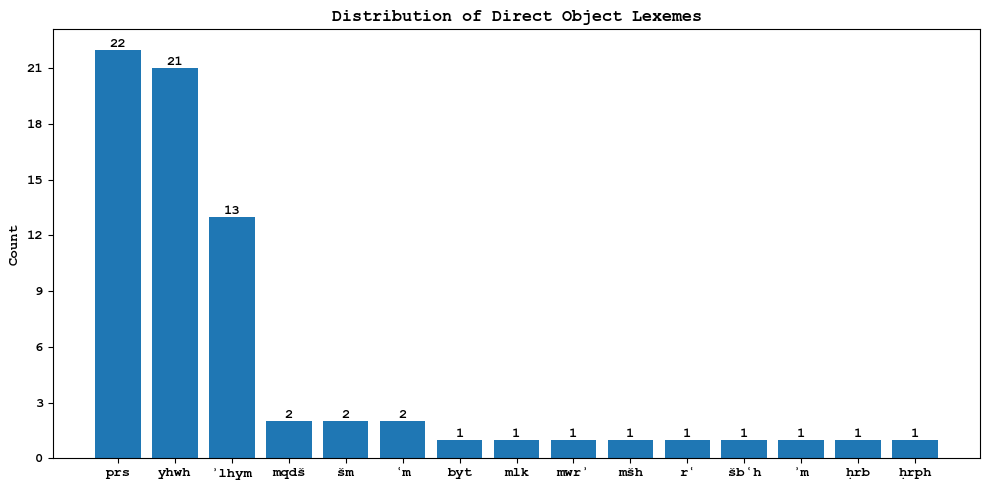

In [207]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator



# Aggregate across topics and sort descending
df_simple = (
    cmpl_lexeme_2nd_by_topic
        .groupby(level=0)
        .sum()
        .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
bars = plt.bar(df_simple.index, df_simple.values)

#plt.xlabel("Direct Object Lexeme")
plt.ylabel("Count")
plt.title("Distribution of Direct Object Lexemes")

# Add count labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        int(height),
        ha="center",
        va="bottom"
    )

# Save outputs
plt.savefig("fig09_DO_lex_distribution.pdf", bbox_inches="tight")
plt.savefig("fig09_DO_lex_distribution.png", dpi=600, bbox_inches="tight")

plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()


In [208]:
cmpl_lexeme_2nd_by_topic = (
    FearValData_DO
        .groupby(["topic", "cmpl_lexeme_2nd sbl_translt", "cmpl_lexeme_2nd"])
        .size()
        .sort_values(ascending=False)
)

cmpl_lexeme_2nd_by_topic


topic                 cmpl_lexeme_2nd sbl_translt  cmpl_lexeme_2nd
YHWH                  yhwh                         יהוה               21
YHWH_suffix           prs                          prs                17
God                   ʾlhym                        אלהים               9
Gods (foreign)        ʾlhym                        אלהים               3
Canaanites_suffix     prs                          prs                 2
YHWH-NameOf           šm                           שׁם                 2
Sanctuary             mqdš                         מקדשׁ               2
King-Og_suffix        prs                          prs                 2
Oath                  šbʿh                         שבעה                1
Sword                 ḥrb                          חרב                 1
People                ʿm                           עם                  1
Parents               ʾm                           אם                  1
Canaanites            ʿm                           עם    

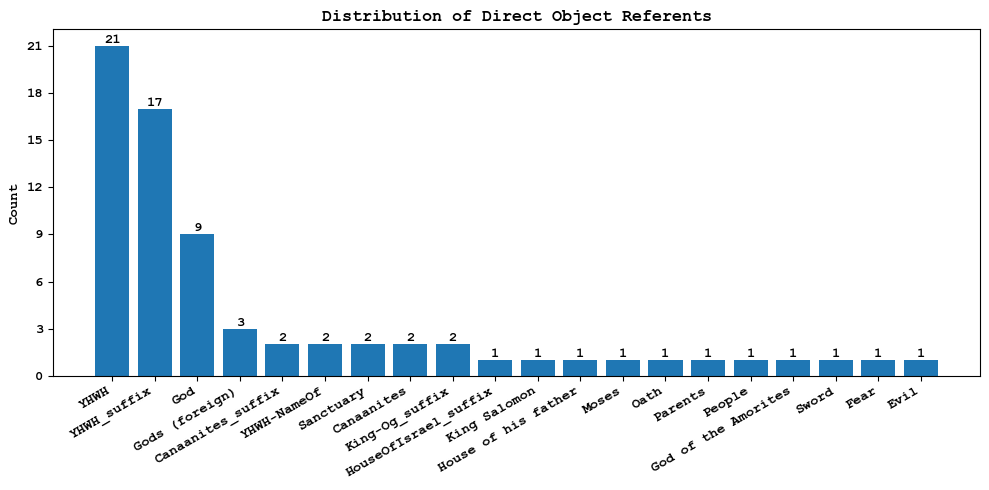

In [209]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator



# Aggregate across topics and sort descending
df_simple = (
    cmpl_lexeme_2nd_by_topic
        .groupby(level=0)
        .sum()
        .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
bars = plt.bar(df_simple.index, df_simple.values)

#plt.xlabel("Direct Object Referents")
plt.ylabel("Count")
plt.title("Distribution of Direct Object Referents")

# Add count labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        int(height),
        ha="center",
        va="bottom"
    )


# Save outputs
plt.savefig("fig10_DO_referent_distribution.pdf", bbox_inches="tight")
plt.savefig("fig10_DO_referent_distribution.png", dpi=600, bbox_inches="tight")

plt.xticks(rotation=30, ha="right")
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()


### Negations with ET

In [210]:
cmpl_lexeme_2nd_with_negation = (
    FearValData_DO
        .groupby(["negation", "speaker", "topic"])
        .size()
        .rename("count")
        .reset_index()
        .sort_values(
            by=["negation", "speaker"],
            ascending=[True, False]
        )
        .set_index(["negation", "speaker", "topic"])
)

cmpl_lexeme_2nd_with_negation


count
negation speaker topic                      
AL       YHWH    Canaanites                1
                 King-Og_suffix            2
         Joshua  Canaanites                1
                 Canaanites_suffix         1
LO       poet    Evil                      1
         YHWH    God of the Amorites       1
                 Gods (foreign)            3
                 HouseOfIsrael_suffix      1
                 YHWH_suffix               2
         Joshua  Canaanites_suffix         1

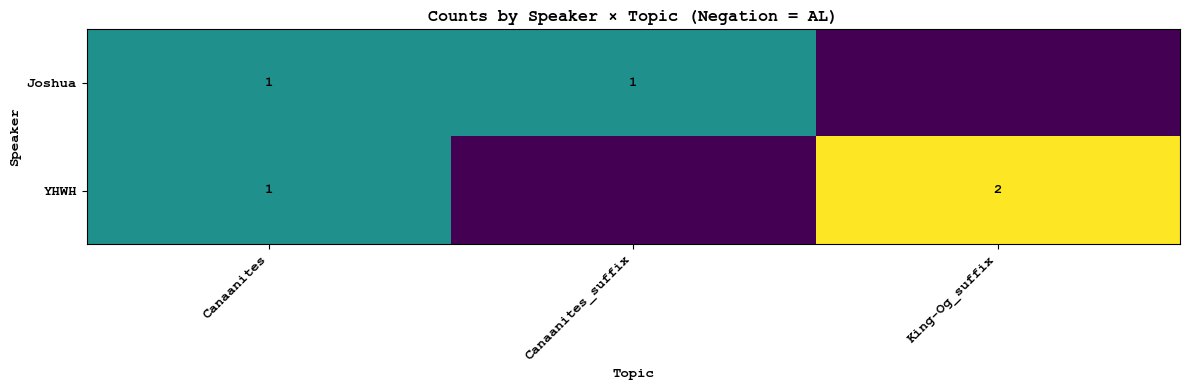

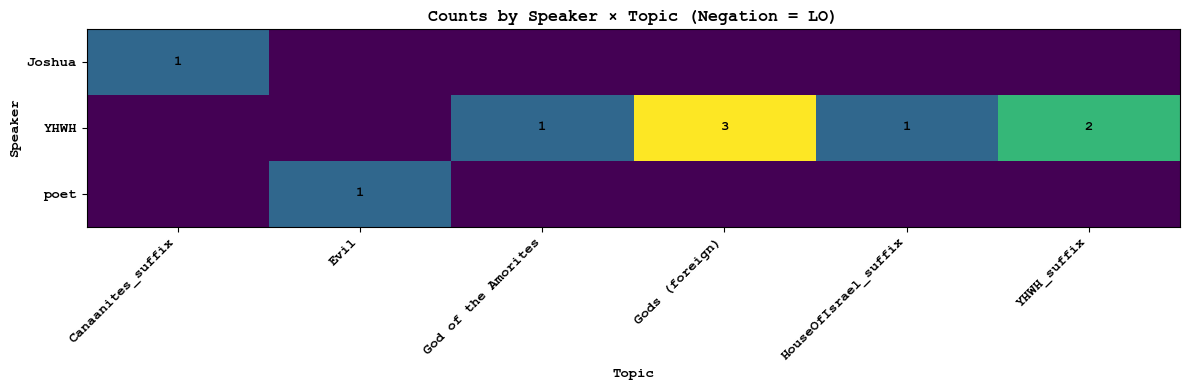

In [211]:
import matplotlib.pyplot as plt

df = cmpl_lexeme_2nd_with_negation.reset_index()

df["topic"] = df["topic"].fillna("—")
df["speaker"] = df["speaker"].fillna("—")
df["negation"] = df["negation"].fillna("—")

for neg in sorted(df["negation"].unique(), key=str):
    sub = df[df["negation"] == neg]

    pivot = sub.pivot_table(
        index="speaker",
        columns="topic",
        values="count",
        aggfunc="sum",
        fill_value=0
    )

    plt.figure(figsize=(12, 4))
    plt.imshow(pivot.values, aspect="auto")

    plt.xticks(range(len(pivot.columns)), pivot.columns, rotation=45, ha="right")
    plt.yticks(range(len(pivot.index)), pivot.index)

    plt.title(f"Counts by Speaker × Topic (Negation = {neg})")
    plt.xlabel("Topic")
    plt.ylabel("Speaker")

    # Add count labels
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = int(pivot.values[i, j])
            if val != 0:
                plt.text(j, i, str(val), ha="center", va="center")

    plt.tight_layout()

    # --- SAVE FIGURES (before show) ---
    safe_neg = str(neg).replace(" ", "_")
    plt.savefig(
        f"fig13_MN_negation_distribution_{safe_neg}.pdf",
        bbox_inches="tight"
    )
    plt.savefig(
        f"fig13_MN_negation_distribution_{safe_neg}.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()


## MN goverened Lexemes

In [212]:
FearValData_all.head()

,order,book,chapter,verse,clause #,clause text,clause text sbl_translt,yrʾ phrase #,yrʾ phrase function,yrʾ phrase text,yrʾ lex sbl_translt,yrʾ gender,yrʾ number,yrʾ person,yrʾ stem,yrʾ tense,complement phrase text,complement phrase function,cmpl_lexeme_1st,cmpl_lexeme_1st sbl_translt,cmpl_lexeme_2nd,cmpl_lexeme_2nd sbl_translt,speaker,negation,topic,suffix,complement type,interpretation,demo,deviation,usable
0,1121,Jesaia,37,6,470949,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,ʾl־tyrʾ mpny hdbrym,781752,Pred,תִּירָא֙,yrʾ,m,sg,p2,qal,impf,מִפְּנֵ֤י הַדְּבָרִים֙,Adju,מן,mn,פנה,pnh,YHWH,AL,Face of the words,NaN,MN_complement,afraid,NaN,NaN,y
1,1108,Josua,9,24,449710,וַנִּירָ֨א מְאֹ֤ד לְנַפְשֹׁתֵ֨ינוּ֙ מִפְּנֵיכֶ֔ם,wnyrʾ mʾd lnpštynw mpnykm,718734,Pred,נִּירָ֨א,yrʾ,unknown,pl,p1,qal,wayq,מִפְּנֵיכֶ֔ם,Adju,מן,mn,פנה,pnh,NaN,NaN,Face of them,y,MN_complement,"NA ""to fear for one's life""",NaN,NaN,y
2,1109,Josua,11,6,449931,אַל־תִּירָ֣א מִפְּנֵיהֶם֒,ʾl־tyrʾ mpnyhm,719406,Pred,תִּירָ֣א,yrʾ,m,sg,p2,qal,impf,מִפְּנֵיהֶם֒,Cmpl,מן,mn,פנה,pnh,YHWH,AL,Face of them,y,MN_complement,afraid,NaN,NaN,y
3,1116,Reges_II,1,15,464848,אַל־תִּירָ֖א מִפָּנָ֑יו,ʾl־tyrʾ mpnyw,764357,Pred,תִּירָ֖א,yrʾ,m,sg,p2,qal,impf,מִפָּנָ֑יו,Cmpl,מן,mn,פנה,pnh,angel of the YHWH,AL,Face of him,y,MN_complement,afraid,NaN,NaN,y
4,1117,Reges_II,19,6,467386,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,ʾl־tyrʾ mpny hdbrym,771792,Pred,תִּירָא֙,yrʾ,m,sg,p2,qal,impf,מִפְּנֵ֤י הַדְּבָרִים֙,Cmpl,מן,mn,פנה,pnh,YHWH,AL,Face of the words,NaN,MN_complement,afraid,NaN,NaN,y


In [213]:
FearValData_all["complement phrase function"].unique()

array(['Adju', 'Cmpl', 'Objc w >T', 'Objc wo ET', 'PreO'], dtype=object)

In [214]:
FearValData_MN = FearValData_all[
                                    (
                                    FearValData_all["complement phrase function"].astype(str).str.contains("Cmpl", na=False)
                                    |
                                    FearValData_all["complement phrase function"].astype(str).str.contains("Adju", na=False)
                                    )
                                    &
                                    (
                                    FearValData_all["usable"] == "y"
                                    )
                                    &
                                    (
                                    FearValData_all["cmpl_lexeme_1st sbl_translt"] == "mn"
                                    )

                                ].copy()


FearValData_MN.head()


,order,book,chapter,verse,clause #,clause text,clause text sbl_translt,yrʾ phrase #,yrʾ phrase function,yrʾ phrase text,yrʾ lex sbl_translt,yrʾ gender,yrʾ number,yrʾ person,yrʾ stem,yrʾ tense,complement phrase text,complement phrase function,cmpl_lexeme_1st,cmpl_lexeme_1st sbl_translt,cmpl_lexeme_2nd,cmpl_lexeme_2nd sbl_translt,speaker,negation,topic,suffix,complement type,interpretation,demo,deviation,usable
0,1121,Jesaia,37,6,470949,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,ʾl־tyrʾ mpny hdbrym,781752,Pred,תִּירָא֙,yrʾ,m,sg,p2,qal,impf,מִפְּנֵ֤י הַדְּבָרִים֙,Adju,מן,mn,פנה,pnh,YHWH,AL,Face of the words,NaN,MN_complement,afraid,NaN,NaN,y
1,1108,Josua,9,24,449710,וַנִּירָ֨א מְאֹ֤ד לְנַפְשֹׁתֵ֨ינוּ֙ מִפְּנֵיכֶ֔ם,wnyrʾ mʾd lnpštynw mpnykm,718734,Pred,נִּירָ֨א,yrʾ,unknown,pl,p1,qal,wayq,מִפְּנֵיכֶ֔ם,Adju,מן,mn,פנה,pnh,NaN,NaN,Face of them,y,MN_complement,"NA ""to fear for one's life""",NaN,NaN,y
2,1109,Josua,11,6,449931,אַל־תִּירָ֣א מִפְּנֵיהֶם֒,ʾl־tyrʾ mpnyhm,719406,Pred,תִּירָ֣א,yrʾ,m,sg,p2,qal,impf,מִפְּנֵיהֶם֒,Cmpl,מן,mn,פנה,pnh,YHWH,AL,Face of them,y,MN_complement,afraid,NaN,NaN,y
3,1116,Reges_II,1,15,464848,אַל־תִּירָ֖א מִפָּנָ֑יו,ʾl־tyrʾ mpnyw,764357,Pred,תִּירָ֖א,yrʾ,m,sg,p2,qal,impf,מִפָּנָ֑יו,Cmpl,מן,mn,פנה,pnh,angel of the YHWH,AL,Face of him,y,MN_complement,afraid,NaN,NaN,y
4,1117,Reges_II,19,6,467386,אַל־תִּירָא֙ מִפְּנֵ֤י הַדְּבָרִים֙,ʾl־tyrʾ mpny hdbrym,771792,Pred,תִּירָא֙,yrʾ,m,sg,p2,qal,impf,מִפְּנֵ֤י הַדְּבָרִים֙,Cmpl,מן,mn,פנה,pnh,YHWH,AL,Face of the words,NaN,MN_complement,afraid,NaN,NaN,y


In [215]:
cmpl_lexeme_2nd = FearValData_MN["cmpl_lexeme_2nd"].value_counts()
cmpl_lexeme_2nd

cmpl_lexeme_2nd
פנה       17
prs       10
אלהים      5
דבר        3
ל          3
פחד        2
אות        1
יהוה       1
מי         1
אנושׁ      1
שׁד        1
שׁלג       1
עבד        1
שׁמועה     1
רבבה       1
חיה        1
אשׁור      1
משׁפט      1
Name: count, dtype: int64

In [216]:
cmpl_lexeme_2nd_by_topic = (
    FearValData_MN
        .groupby(["cmpl_lexeme_2nd sbl_translt", "cmpl_lexeme_2nd", "topic"])
        .size()
        .sort_values(ascending=False)
)

cmpl_lexeme_2nd_by_topic


cmpl_lexeme_2nd sbl_translt  cmpl_lexeme_2nd  topic                         
ʾlhym                        אלהים            God                               5
pnh                          פנה              Face of them                      5
prs                          prs              Israel_suffix                     3
dbr                          דבר              Sons of Israel                    2
pnh                          פנה              Face of JHWH                      2
                                              Face of the words                 2
prs                          prs              Canaanites_suffix                 2
l                            ל                miliphne                          2
pnh                          פנה              Face of Chaldeans                 1
                                              Face of Achisch                   1
ʿbd                          עבד              Chaldeans                         1
ʾšwr                 

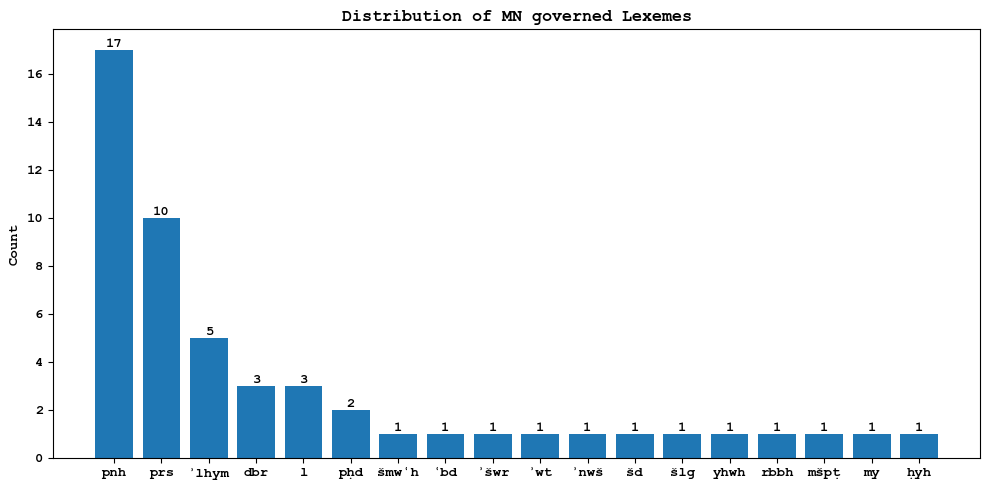

In [217]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator



# Aggregate across topics and sort descending
df_simple = (
    cmpl_lexeme_2nd_by_topic
        .groupby(level=0)
        .sum()
        .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
bars = plt.bar(df_simple.index, df_simple.values)

#plt.xlabel("MN goverened Lexeme")
plt.ylabel("Count")
plt.title("Distribution of MN governed Lexemes")

# Add count labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        int(height),
        ha="center",
        va="bottom"
    )

# Save outputs
plt.savefig("fig11_MN_lex_distribution.pdf", bbox_inches="tight")
plt.savefig("fig11_MN_lex_distribution.png", dpi=600, bbox_inches="tight")

plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()


In [218]:
cmpl_lexeme_2nd_by_topic = (
    FearValData_MN
        .groupby(["topic", "cmpl_lexeme_2nd sbl_translt", "cmpl_lexeme_2nd"])
        .size()
        .sort_values(ascending=False)
)

cmpl_lexeme_2nd_by_topic


topic                           cmpl_lexeme_2nd sbl_translt  cmpl_lexeme_2nd
Face of them                    pnh                          פנה                5
God                             ʾlhym                        אלהים              5
Israel_suffix                   prs                          prs                3
Sons of Israel                  dbr                          דבר                2
Face of the words               pnh                          פנה                2
Face of JHWH                    pnh                          פנה                2
Canaanites_suffix               prs                          prs                2
miliphne                        l                            ל                  2
Terror of the night             pḥd                          פחד                1
Terror (sudden)                 pḥd                          פחד                1
Sons of Israel_suffix           prs                          prs                1
God                  

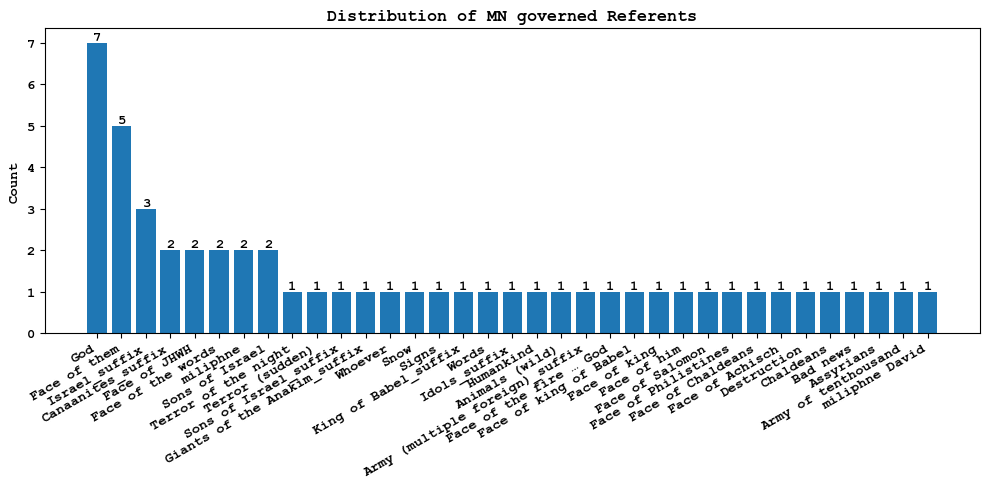

In [219]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator



# Aggregate across topics and sort descending
df_simple = (
    cmpl_lexeme_2nd_by_topic
        .groupby(level=0)
        .sum()
        .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
bars = plt.bar(df_simple.index, df_simple.values)

#plt.xlabel("MN governed Referents")
plt.ylabel("Count")
plt.title("Distribution of MN governed Referents")

# Add count labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        int(height),
        ha="center",
        va="bottom"
    )


# Save outputs
plt.savefig("fig12_MN_lex_distribution.pdf", bbox_inches="tight")
plt.savefig("fig12_MN_lex_distribution.png", dpi=600, bbox_inches="tight")

plt.xticks(rotation=30, ha="right")
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()


### Negations with MN

In [220]:
cmpl_lexeme_2nd_with_negation = (
    FearValData_MN
        .groupby(["negation", "speaker", "topic"])
        .size()
        .rename("count")
        .reset_index()
        .sort_values(
            by=["negation", "speaker"],
            ascending=[True, False]
        )
        .set_index(["negation", "speaker", "topic"])
)

cmpl_lexeme_2nd_with_negation


count
negation speaker           topic                                
AL       angel of the YHWH Face of him                         1
         YHWH              Assyrians                           1
                           Canaanites_suffix                   1
                           Face of king of Babel               1
                           Face of the words                   2
                           Face of them                        2
                           Idols_suffix                        1
                           King of Babel_suffix                1
                           Sons of Israel                      2
                           Sons of Israel_suffix               1
         Wiseman           Terror (sudden)                     1
         Nehemiah          Face of them                        1
         Gedaliah          Chaldeans                           1
         Elifas            Animals (wild)                      1
LO       wiseman           Snow                                1
         poet              Army of tenthousand                 1
                           Terror of the night                 1
         Moses             Army (multiple foreign)_suffix      1
                           Canaanites_suffix                   1
                           Giants of the Anakim_suffix         1
         Elifas            Destruction                         1

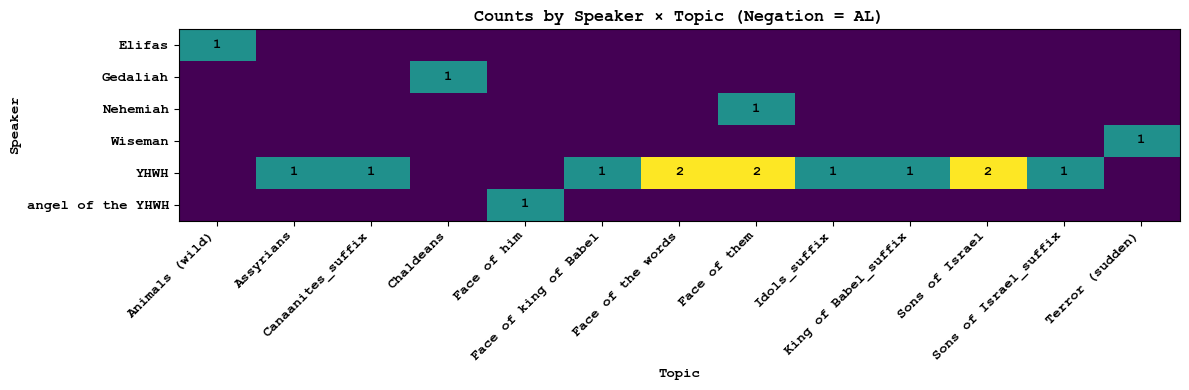

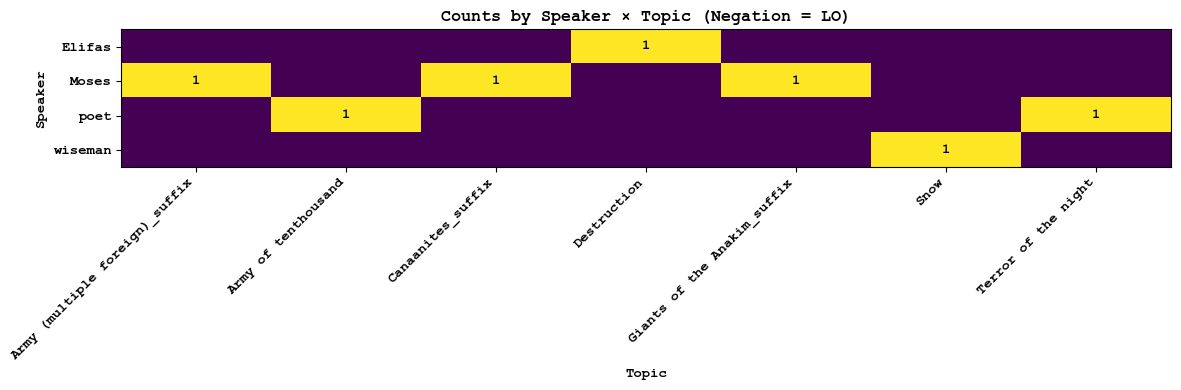

In [221]:
import matplotlib.pyplot as plt

df = cmpl_lexeme_2nd_with_negation.reset_index()

df["topic"] = df["topic"].fillna("—")
df["speaker"] = df["speaker"].fillna("—")
df["negation"] = df["negation"].fillna("—")

for neg in sorted(df["negation"].unique(), key=str):
    sub = df[df["negation"] == neg]

    pivot = sub.pivot_table(
        index="speaker",
        columns="topic",
        values="count",
        aggfunc="sum",
        fill_value=0
    )

    plt.figure(figsize=(12, 4))
    plt.imshow(pivot.values, aspect="auto")

    plt.xticks(range(len(pivot.columns)), pivot.columns, rotation=45, ha="right")
    plt.yticks(range(len(pivot.index)), pivot.index)

    plt.title(f"Counts by Speaker × Topic (Negation = {neg})")
    plt.xlabel("Topic")
    plt.ylabel("Speaker")

    # Add count labels
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = int(pivot.values[i, j])
            if val != 0:
                plt.text(j, i, str(val), ha="center", va="center")

    plt.tight_layout()

    # --- SAVE FIGURES (before show) ---
    safe_neg = str(neg).replace(" ", "_")
    plt.savefig(
        f"fig13_MN_negation_distribution_{safe_neg}.pdf",
        bbox_inches="tight"
    )
    plt.savefig(
        f"fig13_MN_negation_distribution_{safe_neg}.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()


## Negations and Valence

In [222]:
neg_by_phrase_function = (
    FearValData_all
        .groupby(["negation", "complement type"])
        .size()
        .rename("count")
        .reset_index()
        .sort_values(
            by=["negation", "complement type"],
            ascending=[True, True]
        )
        .set_index(["negation", "complement type"])
)

neg_by_phrase_function


count
negation complement type       
AL       DO_complement        5
         MN_complement       17
LO       DO_complement       16
         MN_complement        8

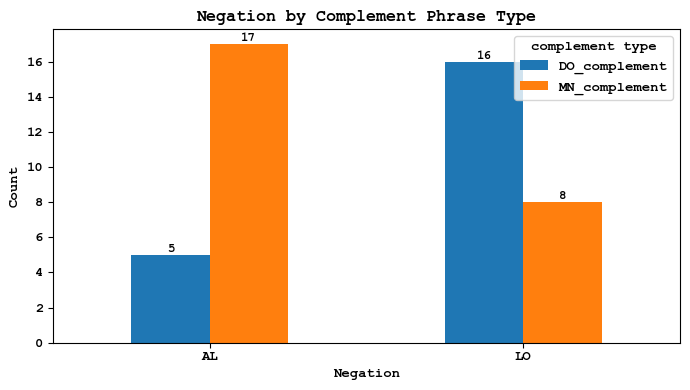

In [223]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

df_plot = neg_by_phrase_function.reset_index()

pivot = df_plot.pivot(
    index="negation",
    columns="complement type",
    values="count"
).fillna(0)

ax = pivot.plot(kind="bar", figsize=(7, 4))

ax.set_xlabel("Negation")
ax.set_ylabel("Count")
ax.set_title("Negation by Complement Phrase Type")

# Force integer ticks
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

# --- Explicit negation labels ---
ax.set_xticklabels(["AL", "LO"], rotation=0)

# --- Add count labels on bars ---
for container in ax.containers:
    ax.bar_label(container, label_type="edge", fontsize=9)

plt.tight_layout()

# Save high-resolution output
fig = ax.get_figure()
fig.savefig("fig14_negation_complement_type_distribution.pdf", bbox_inches="tight")
fig.savefig("fig14_negation_complement_type_distribution.png", dpi=600, bbox_inches="tight")

plt.show()
